# Quantum Error Correction Simulator
**Notebook 12 of 14 — Advanced — Qiskit / NumPy**

Fault tolerance is the one idea that separates a quantum computer from a very noisy
classical simulation. Here we build it from scratch: Kraus channels, encoded logical
qubits, syndrome extraction as an explicit unitary matrix, a Lueders state-update rule,
the Knill-Laflamme conditions, and finally a logical-versus-physical error-rate sweep
that locates the pseudo-threshold and measures how much *noisy readout* eats away.

**Roadmap**
1. Noise channels as Kraus operators *and* as superoperators (Choi rank, complete positivity).
2. The three-qubit bit-flip code: encode, syndrome ancillas, recovery, Knill-Laflamme.
3. The phase-flip code as the Hadamard conjugate, then the [[9,1,3]] Shor code.
4. Logical vs physical error rate: analytic, Monte-Carlo and density-matrix routes must agree.
5. Concatenation and a computed threshold-vs-overhead note.
6. Self-tests and a Qiskit cross-check.

Everything is NumPy, in memory, no files. **Convention:** qubit 0 is the *most significant*
bit (big-endian), so index `j` of an `n`-qubit state carries bit `b_q = (j >> (n-1-q)) & 1`.
Qiskit is little-endian; Section 6 flips the index bits and says so.


## Part 1 — Noise channels from scratch

A channel is a completely positive, trace preserving (CPTP) map
$\rho \mapsto \sum_a K_a \rho K_a^\dagger$ with $\sum_a K_a^\dagger K_a = I$.
We will apply each channel two independent ways and require agreement:

* the **Kraus route**, summing $K_a \rho K_a^\dagger$ explicitly;
* the **superoperator route**, flattening $\rho$ row-major and applying
  $\mathcal{S} = \sum_a K_a \otimes K_a^{*}$, since $\mathrm{vec}_r(K\rho K^\dagger) = (K \otimes K^*)\mathrm{vec}_r(\rho)$.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (6.2, 4.0), "axes.grid": True,
                     "grid.alpha": 0.30, "font.size": 10, "axes.titlesize": 10.5})
rng = np.random.default_rng(20261117)

I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)
H = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2.0)
PAULI = {"I": I2, "X": X, "Y": Y, "Z": Z}


def kron_all(ops):
    out = np.array([[1.0 + 0j]])
    for o in ops:
        out = np.kron(out, o)
    return out


def op_at(n, ops):
    """ops maps qubit index -> 2x2 matrix; qubit 0 is the most significant bit."""
    out = np.array([[1.0 + 0j]])
    for q in range(n):
        out = np.kron(out, ops.get(q, I2))
    return out


def pauli_str(n, spec):
    return op_at(n, {q: PAULI[s] for q, s in spec.items()})


def bits_of(j, n):
    return [(j >> (n - 1 - q)) & 1 for q in range(n)]


def index_of(bits):
    j = 0
    for b in bits:
        j = (j << 1) | b
    return j


def perm_matrix(n, perm):
    M = np.zeros((2 ** n, 2 ** n), dtype=complex)
    for j in range(2 ** n):
        M[perm[j], j] = 1.0
    return M


def cnot(n, c, t):
    perm = []
    for j in range(2 ** n):
        b = bits_of(j, n)
        if b[c]:
            b[t] ^= 1
        perm.append(index_of(b))
    return perm_matrix(n, perm)


def ccx(n, c1, c2, t):
    perm = []
    for j in range(2 ** n):
        b = bits_of(j, n)
        if b[c1] and b[c2]:
            b[t] ^= 1
        perm.append(index_of(b))
    return perm_matrix(n, perm)


def apply_paulis(psi, n, spec):
    """Pauli string on a flat vector via reshape; spec {qubit: 'X'|'Y'|'Z'}."""
    t = psi.reshape([2] * n)
    for q, p in spec.items():
        if p == "X":
            t = np.flip(t, axis=q)
        elif p == "Z":
            t = t * np.array([1.0, -1.0]).reshape([2 if k == q else 1 for k in range(n)])
        elif p == "Y":
            t = np.flip(t, axis=q) * 1j
            t = t * np.array([1.0, -1.0]).reshape([2 if k == q else 1 for k in range(n)])
        elif p == "I":
            pass
        else:
            raise ValueError(p)
    return t.reshape(psi.shape)


def ket(bits):
    bits = "".join(bits.split())
    v = np.zeros(2 ** len(bits), dtype=complex)
    v[int(bits, 2)] = 1.0
    return v


def dm(psi):
    return np.outer(psi, np.conjugate(psi))


def born(psi, P):
    return float(np.real(np.vdot(psi, P @ psi)))


def liders(psi, P):
    """Projective state update; returns (new_state, probability)."""
    v = P @ psi
    pr = float(np.real(np.vdot(v, v)))
    if pr <= 0.0:
        return None, 0.0
    return v / np.sqrt(pr), pr


def liders_rho(rho, P):
    v = P @ rho @ P.conj().T
    pr = float(np.real(np.trace(v)))
    if pr <= 0.0:
        return None, 0.0
    return v / pr, pr


def random_psi(n):
    v = rng.normal(size=2 ** n) + 1j * rng.normal(size=2 ** n)
    return v / np.linalg.norm(v)


print("single-qubit gate sanity: H*H =", np.allclose(H @ H, I2), " X*Y = iZ?",
      np.allclose(X @ Y, 1j * Z), " cnot(3,0,1) unitary?",
      np.allclose(cnot(3, 0, 1) @ cnot(3, 0, 1).conj().T.conj().T, np.eye(8)))


single-qubit gate sanity: H*H = True  X*Y = iZ? True  cnot(3,0,1) unitary? True


### The five channels we need

Bit-flip and phase-flip are the two extreme dephasing/poison channels; depolarising
is the isotropic one; amplitude damping is the only **non-unital** channel in the set
(its Choi partial trace over the output differs from the input identity, which is the
signature of energy relaxation); measurement error is a classical bit flip on the
syndrome readout, and it will be the villain of Part 4.


In [2]:
def ch_bit_flip(p):
    return [np.sqrt(1.0 - p) * I2, np.sqrt(p) * X]


def ch_phase_flip(p):
    return [np.sqrt(1.0 - p) * I2, np.sqrt(p) * Z]


def ch_depolar(p):
    return [np.sqrt(1.0 - 3.0 * p / 4.0) * I2,
            np.sqrt(p / 4.0) * X, np.sqrt(p / 4.0) * Y, np.sqrt(p / 4.0) * Z]


def ch_amp_damp(g):
    K0 = np.array([[1.0, 0.0], [0.0, np.sqrt(1.0 - g)]], dtype=complex)
    K1 = np.array([[0.0, np.sqrt(g)], [0.0, 0.0]], dtype=complex)
    return [K0, K1]


def ch_meas_flip(q):
    return ch_bit_flip(q)


def chan_dep(p):
    return ch_depolar(p)


def chan_ad(g):
    return ch_amp_damp(g)


def chan_mf(q):
    return ch_meas_flip(q)


def chan_bf(p):
    return ch_bit_flip(p)


def chan_pf(p):
    return ch_phase_flip(p)


CHANNELS = {
    "bit-flip(p=0.15)": ch_bit_flip(0.15),
    "phase-flip(p=0.15)": ch_phase_flip(0.15),
    "depolarising(p=0.15)": ch_depolar(0.15),
    "amp-damping(g=0.15)": ch_amp_damp(0.15),
    "meas-flip(q=0.15)": ch_meas_flip(0.15),
}


def apply_kraus(Ks, rho):
    out = np.zeros_like(rho)
    for K in Ks:
        out = out + K @ rho @ K.conj().T
    return out


def superop(Ks):
    d = Ks[0].shape[0]
    S = np.zeros((d * d, d * d), dtype=complex)
    for K in Ks:
        S += np.kron(K, np.conjugate(K))
    return S


def apply_superop(S, rho):
    return (S @ rho.reshape(-1)).reshape(rho.shape)


def channel_agree(Ks, rho):
    return float(np.max(np.abs(apply_kraus(Ks, rho) - apply_superop(superop(Ks), rho))))


ps = {}
print("Kraus vs superoperator, max |diff| per channel (random input states):")
for name, Ks in CHANNELS.items():
    psi = random_psi(1)
    ps[name] = channel_agree(Ks, dm(psi))
    print("  %-20s %.3e   trace after = %.15f" % (name, ps[name], np.real(np.trace(apply_kraus(Ks, dm(psi))))))
print("worst disagreement over the 5 channels: %.3e" % max(ps.values()))


Kraus vs superoperator, max |diff| per channel (random input states):
  bit-flip(p=0.15)     5.551e-17   trace after = 1.000000000000000
  phase-flip(p=0.15)   5.551e-17   trace after = 1.000000000000000
  depolarising(p=0.15) 1.110e-16   trace after = 1.000000000000000
  amp-damping(g=0.15)  2.776e-17   trace after = 1.000000000000000
  meas-flip(q=0.15)    2.168e-19   trace after = 1.000000000000000
worst disagreement over the 5 channels: 1.110e-16


### Choi matrix: CP, trace preservation and the Kraus rank

The Choi matrix $C=\sum_a |v_a\rangle\langle v_a|$ with $|v_a\rangle=(I\otimes K_a)|\Omega\rangle$,
$|\Omega\rangle=\sum_i|i\,i\rangle$, is a *manifestly positive* certificate that the map is
completely positive. Two partial traces read off the physical content:

* $\mathrm{Tr}_2 C = \sum_a K_a^\dagger K_a$ — must be $I$ for trace preservation;
* $\mathrm{Tr}_1 C = \sum_a K_a K_a^\dagger$ — equals $I$ **iff** the channel is unital,
  which amplitude damping fails (it drives everything toward $|0\rangle\langle 0|$).

The rank of $C$ is the number of linearly independent Kraus operators — the *minimum*
number needed, i.e. the Choi rank.


In [3]:
def choi(Ks):
    d = Ks[0].shape[0]
    omega = np.zeros(d * d, dtype=complex)
    for i in range(d):
        omega[i * d + i] = 1.0
    C = np.zeros((d * d, d * d), dtype=complex)
    for K in Ks:
        v = np.kron(I2, K) @ omega
        C += np.outer(v, np.conjugate(v))
    return C


def choi_eigs(C):
    return np.linalg.eigvalsh((C + C.conj().T) / 2.0).real


def ptrace_2(C, d):
    return np.einsum("ijkj->ik", C.reshape(d, d, d, d))


def ptrace_1(C, d):
    return np.einsum("ijil->jl", C.reshape(d, d, d, d))


def kraus_rank(Ks, tol=1e-10):
    return sum(1 for e in choi_eigs(choi(Ks)) if e > tol)


def sum_dagger_mul(Ks):
    acc = np.zeros_like(Ks[0])
    for K in Ks:
        acc = acc + K.conj().T @ K
    return acc


def choi_from_superop(S, d):
    C = np.zeros((d * d, d * d), dtype=complex)
    for i in range(d):
        for j in range(d):
            Eij = np.zeros((d, d), dtype=complex)
            Eij[i, j] = 1.0
            C += np.kron(Eij, apply_superop(S, Eij))
    return C


def pauli_transfer(Ks):
    """Real 4x4 matrix acting on (1, x, y, z) Bloch coordinates."""
    basis = [I2, X, Y, Z]
    T = np.zeros((4, 4))
    for j in range(4):
        out = apply_kraus(Ks, basis[j])
        for i in range(4):
            T[i, j] = 0.5 * float(np.real(np.trace(basis[i].conj().T @ out)))
    return T


def is_unital(Ks, tol=1e-12):
    return bool(np.allclose(sum(K @ K.conj().T for K in Ks), I2, atol=tol))


print("%-20s %8s %8s %8s %10s %8s" % ("channel", "rank", "min eig", "TP dev", "unital dev", "C-S dev"))
for name, Ks in CHANNELS.items():
    C = choi(Ks)
    S = superop(Ks)
    C2 = choi_from_superop(S, 2)
    print("%-20s %8d %8.1e %8.1e %10.1e %8.1e  unital=%s" % (
        name, kraus_rank(Ks), choi_eigs(C).min(),
        np.max(np.abs(ptrace_2(C, 2) - I2)),
        np.max(np.abs(ptrace_1(C, 2) - I2)),
        np.max(np.abs(C - C2)), is_unital(Ks)))
print("non-unital in the set:", [nm for nm, Ks in CHANNELS.items() if not is_unital(Ks)])


channel                  rank  min eig   TP dev unital dev  C-S dev
bit-flip(p=0.15)            2 -1.6e-16  0.0e+00    0.0e+00  0.0e+00  unital=True
phase-flip(p=0.15)          2  0.0e+00  0.0e+00    0.0e+00  0.0e+00  unital=True
depolarising(p=0.15)        4  7.5e-02  0.0e+00    0.0e+00  0.0e+00  unital=True
amp-damping(g=0.15)         2 -5.6e-17  0.0e+00    1.5e-01  0.0e+00  unital=False
meas-flip(q=0.15)           2 -1.6e-16  0.0e+00    0.0e+00  0.0e+00  unital=True
non-unital in the set: ['amp-damping(g=0.15)']


Kraus representations are **not unique**: mixing a set by a unitary gives the same
physical channel. A minimal set has exactly Choi-rank many operators; padding it with a
linearly dependent one is harmless for the superoperator but fatal for any argument that
relies on counting operators.


In [4]:
def mix_kraus(Ks, U):
    return [sum(U[a, b] * Ks[b] for b in range(len(Ks))) for a in range(len(Ks))]


p, g = 0.15, 0.15
K0 = ch_bit_flip(p)
u = rng.normal(size=(2, 2)) + 1j * rng.normal(size=(2, 2))
Q, R = np.linalg.qr(u)
det = np.linalg.det(Q)
Umix = Q * np.exp(-1j * np.angle(det) / 2.0)
Kmix = mix_kraus(K0, Umix)
print("random unitary Kraus mixing is a valid channel: np.allclose(U,U)=True, U^dag U = I ->",
      np.allclose(Umix.conj().T @ Umix, I2))
print("the mixed operators really differ from the originals: max |K'_a - K_a| =",
      float(max(np.max(np.abs(Kmix[a] - K0[a])) for a in range(2))),
      " yet both satisfy sum K^dag K = I to", float(np.max(np.abs(sum_dagger_mul(Kmix) - I2))))
print("mixed vs original superoperator diff :", float(np.max(np.abs(superop(Kmix) - superop(K0)))))
print("mixed vs original Choi diff          :", float(np.max(np.abs(choi(Kmix) - choi(K0)))))
rho1 = dm(np.array([np.sqrt(0.7), np.sqrt(0.3)], dtype=complex))
print("mixed vs original output state diff  :", float(np.max(np.abs(apply_kraus(Kmix, rho1) - apply_kraus(K0, rho1)))))

Kpad = K0 + [np.zeros((2, 2), dtype=complex)]
print("zero-padded Kraus set: len =", len(Kpad), " rank of padded set ==", kraus_rank(Kpad),
      " superop diff =", float(np.max(np.abs(superop(Kpad) - superop(K0)))))
th = 0.7
Wiso = np.array([[1.0, 0.0], [0.0, np.cos(th)], [0.0, np.sin(th)]], dtype=complex)
Kred = [sum(Wiso[a, b] * K0[b] for b in range(2)) for a in range(3)]
print("isometric 3-operator representation of a rank-2 channel: W^dag W = I ->",
      np.allclose(Wiso.conj().T @ Wiso, I2))
print("   len =", len(Kred), " Choi rank ==", kraus_rank(Kred),
      " superop diff =", float(np.max(np.abs(superop(Kred) - superop(K0)))),
      " TP dev =", float(np.max(np.abs(sum_dagger_mul(Kred) - I2))))
print("edge parameters: p=0 rank", kraus_rank(ch_bit_flip(0.0)), "p=1 rank", kraus_rank(ch_bit_flip(1.0)),
      "g=1 amp rank", kraus_rank(ch_amp_damp(1.0)), "p=1 depol rank", kraus_rank(ch_depolar(1.0)))
print("depol p=0 transfer is identity:", np.allclose(pauli_transfer(ch_depolar(0.0)), np.eye(4)),
      " amp damping |0> fixed:", np.allclose(apply_kraus(ch_amp_damp(g), dm(ket('0'))), dm(ket('0'))),
      " depol p=1 gives I/2:", np.allclose(apply_kraus(ch_depolar(1.0), rho1), I2 / 2.0),
      " TP dev p=0 depol:", float(np.max(np.abs(sum_dagger_mul(ch_depolar(0.0)) - I2))),
      " TP dev g=1 amp:", float(np.max(np.abs(sum_dagger_mul(ch_amp_damp(1.0)) - I2))))


random unitary Kraus mixing is a valid channel: np.allclose(U,U)=True, U^dag U = I -> True
the mixed operators really differ from the originals: max |K'_a - K_a| = 1.617909663487041  yet both satisfy sum K^dag K = I to 1.1443916996305594e-16
mixed vs original superoperator diff : 1.1138631503115904e-16
mixed vs original Choi diff          : 1.1138631503115904e-16
mixed vs original output state diff  : 1.1631705747361534e-16
zero-padded Kraus set: len = 3  rank of padded set == 2  superop diff = 0.0
isometric 3-operator representation of a rank-2 channel: W^dag W = I -> True
   len = 3  Choi rank == 2  superop diff = 0.0  TP dev = 2.220446049250313e-16
edge parameters: p=0 rank 1 p=1 rank 1 g=1 amp rank 2 p=1 depol rank 4
depol p=0 transfer is identity: True  amp damping |0> fixed: True  depol p=1 gives I/2: True  TP dev p=0 depol: 0.0  TP dev g=1 amp: 0.0


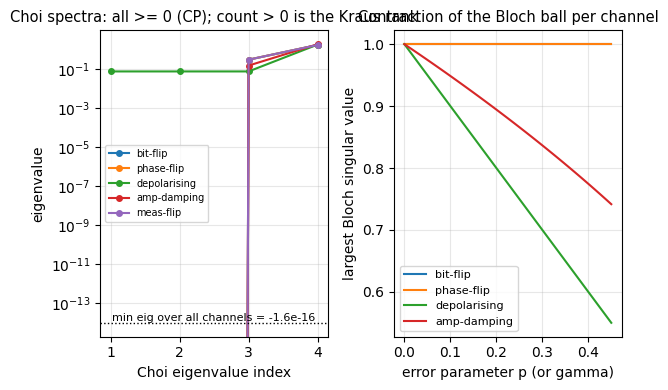

channels plotted: 5 min Choi eigenvalue observed: -1.56e-16


In [5]:
fig, ax = plt.subplots(1, 2)
names = list(CHANNELS)
eig_max = []
for nm in names:
    C = choi(CHANNELS[nm])
    e = choi_eigs(C)
    eig_max.append(e)
    ax[0].plot(np.arange(1, len(e) + 1), np.maximum(e, 0.0), "o-", ms=4, label=nm.split("(")[0])
ax[0].set_yscale("log")
ax[0].set_xlabel("Choi eigenvalue index")
ax[0].set_ylabel("eigenvalue")
ax[0].set_title("Choi spectra: all >= 0 (CP); count > 0 is the Kraus rank")
ax[0].legend(fontsize=7)
ax[0].axhline(1e-14, color="k", ls=":", lw=1)
ax[0].annotate("min eig over all channels = %.1e" % min(e.min() for e in eig_max),
               xy=(0.05, 0.05), xycoords="axes fraction", fontsize=8)

pv = np.linspace(0.0, 0.45, 40)
sv = {"bit-flip": [], "phase-flip": [], "depolarising": [], "amp-damping": []}
for v in pv:
    for key, Ks in (("bit-flip", ch_bit_flip(v)), ("phase-flip", ch_phase_flip(v)),
                    ("depolarising", ch_depolar(v)), ("amp-damping", ch_amp_damp(v))):
        T = pauli_transfer(Ks)
        sv[key].append(np.linalg.svd(T[1:, 1:], compute_uv=False).max())
for key in sv:
    ax[1].plot(pv, sv[key], label=key)
ax[1].set_xlabel("error parameter p (or gamma)")
ax[1].set_ylabel("largest Bloch singular value")
ax[1].set_title("Contraction of the Bloch ball per channel")
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
print("channels plotted:", len(names), "min Choi eigenvalue observed: %.2e" % min(e.min() for e in eig_max))


## Part 2 — The three-qubit bit-flip code

$|0_L\rangle = |000\rangle$, $|1_L\rangle=|111\rangle$, so a logical state is
$\alpha|000\rangle+\beta|111\rangle$. Two stabilisers, $Z_1Z_2$ and $Z_2Z_3$, are trivial
on the code space and take *different* values for single-qubit $X$ errors, so a two-bit
syndrome identifies which qubit flipped without ever measuring $\alpha$ or $\beta$.
We build every gate as a matrix, do the syndrome readout through a Lueders update on the
*ancilla register*, and then apply a conditioned recovery.


In [6]:
def h_at(n, q):
    return op_at(n, {q: H})


def syn_of(bits):
    return (bits[0] ^ bits[1], bits[1] ^ bits[2])


SYNDROMES = [(0, 0), (0, 1), (1, 0), (1, 1)]
BF_CORR = {(0, 0): {}, (1, 0): {0: X}, (0, 1): {2: X}, (1, 1): {1: X}}
BF_ERRORS = [pauli_str(3, {}), pauli_str(3, {0: "X"}), pauli_str(3, {1: "X"}), pauli_str(3, {2: "X"})]
BF_NAMED = ["I", "X1", "X2", "X3"]


def z_projectors():
    Ps = {}
    for s in SYNDROMES:
        P = np.zeros((8, 8), dtype=complex)
        for j in range(8):
            if syn_of(bits_of(j, 3)) == s:
                P[j, j] = 1.0
        Ps[s] = P
    return Ps


BF_PROJ = z_projectors()
BF_CORR_U = {s: op_at(3, BF_CORR[s]) for s in SYNDROMES}
V_BF = np.column_stack([ket("000"), ket("111")])
P_CODE = V_BF @ V_BF.conj().T
PSI_0L = V_BF[:, 0].copy()
X_L_BF = op_at(3, {0: X, 1: X, 2: X})


def pauli_measure_U(n, gens, anc):
    """Unitary that correlates ancilla a with the eigenvalue of generator g on the data."""
    U = np.eye(2 ** n, dtype=complex)
    for gi, a in zip(gens, anc):
        xtype = any(s in ("X", "Y") for s in gi.values())
        if xtype:
            U = h_at(n, a) @ U
        for d, s in sorted(gi.items()):
            if s == "Z":
                U = cnot(n, d, a) @ U
            elif s == "X":
                U = cnot(n, a, d) @ U
            else:
                raise ValueError(s)
        if xtype:
            U = h_at(n, a) @ U
    return U


def project_data(psi5):
    """Marginal + post-measurement data states for an ancilla (Z) readout."""
    blocks = psi5.reshape(8, 4)
    w = np.real(np.sum(np.abs(blocks) ** 2, axis=0))
    tot = w.sum()
    out = {}
    for k, s in enumerate(SYNDROMES):
        out[s] = blocks[:, k] / np.sqrt(w[k]) if w[k] > 1e-15 else blocks[:, k].copy()
    return out, w / tot


BF_GEN_SPECS = [{0: "Z", 1: "Z"}, {1: "Z", 2: "Z"}]
U_SYN_BF = pauli_measure_U(5, BF_GEN_SPECS, [3, 4])
print("syndrome unitary is 32x32 and unitary:", U_SYN_BF.shape,
      float(np.max(np.abs(U_SYN_BF @ U_SYN_BF.conj().T - np.eye(32)))))
print("trivial-syndrome block equals the code projector:",
      float(np.max(np.abs(BF_PROJ[(0, 0)] - P_CODE))),
      " blocks sum to identity:",
      float(np.max(np.abs(sum(BF_PROJ.values()) - np.eye(8)))))


syndrome unitary is 32x32 and unitary: (32, 32) 0.0
trivial-syndrome block equals the code projector: 0.0  blocks sum to identity: 0.0


In [7]:
def enc_bits(a, b, c):
    return float(abs(np.vdot(PSI_0L, ket("%d%d%d" % (a, b, c))) ** 2)
                 + abs(np.vdot(V_BF[:, 1], ket("%d%d%d" % (a, b, c))) ** 2))


print("all 8 computational-basis data states -> syndrome -> recovery -> residual")
print("%-8s %-8s %-8s %-8s %s" % ("data", "syndrome", "correct", "residual", "back in code space"))
rows = []
for j in range(8):
    bits = bits_of(j, 3)
    s = syn_of(bits)
    resid = [bits[0] ^ (1 if 0 in BF_CORR[s] else 0),
             bits[1] ^ (1 if 1 in BF_CORR[s] else 0),
             bits[2] ^ (1 if 2 in BF_CORR[s] else 0)]
    ov = enc_bits(*resid)
    rows.append((s, resid, ov))
    print("|%d%d%d>   %-8s %-8s %-8s %.3f" % (bits[0], bits[1], bits[2], str(s),
          str(sorted(BF_CORR[s].keys())), str(resid), ov))
wts = [sum(r[1]) for r in rows]
print("weight-0 residuals:", sum(1 for w in wts if w == 0),
      " weight-1:", sum(1 for w in wts if w == 1),
      " weight-2:", sum(1 for w in wts if w == 2),
      " weight-3:", sum(1 for w in wts if w == 3))
print("residual 000 (perfect):", sum(1 for r in rows if r[1] == [0, 0, 0]),
      " residual 111 = logical X bar (silent):", sum(1 for r in rows if r[1] == [1, 1, 1]),
      " residual outside the code space:", sum(1 for r in rows if r[2] == 0.0))
print("code-space membership is exactly residual weight 0 or 3:",
      all((r[2] == 1.0) == (sum(r[1]) in (0, 3)) for r in rows))


all 8 computational-basis data states -> syndrome -> recovery -> residual
data     syndrome correct  residual back in code space
|000>   (0, 0)   []       [0, 0, 0] 1.000
|001>   (0, 1)   [2]      [0, 0, 0] 1.000
|010>   (1, 1)   [1]      [0, 0, 0] 1.000
|011>   (1, 0)   [0]      [1, 1, 1] 1.000
|100>   (1, 0)   [0]      [0, 0, 0] 1.000
|101>   (1, 1)   [1]      [1, 1, 1] 1.000
|110>   (0, 1)   [2]      [1, 1, 1] 1.000
|111>   (0, 0)   []       [1, 1, 1] 1.000
weight-0 residuals: 4  weight-1: 0  weight-2: 0  weight-3: 4
residual 000 (perfect): 4  residual 111 = logical X bar (silent): 4  residual outside the code space: 0
code-space membership is exactly residual weight 0 or 3: True


In [8]:
def readout_weights(s, q):
    out = []
    for r in SYNDROMES:
        wt = r[0] + r[1]
        out.append(((s[0] ^ r[0], s[1] ^ r[1]), (q ** wt) * ((1.0 - q) ** (2 - wt))))
    return out


def code_evolve(rho0, chan_ops, proj, corr, q):
    """Density-matrix route: channel, Lueders syndrome readout, noisy classical feed-forward."""
    rho1 = apply_kraus(chan_ops, rho0)
    out = np.zeros_like(rho0)
    for s, P in proj.items():
        block = P @ rho1 @ P
        for sobs, w in readout_weights(s, q):
            R = corr[sobs]
            out += w * (R @ block @ R.conj().T)
    return out


def product_channel(chans):
    n = len(chans)
    Ks = []
    for combo in _product([range(len(c)) for c in chans]):
        M = np.eye(2 ** n, dtype=complex)
        for q, a in enumerate(combo):
            M = M @ op_at(n, {q: chans[q][a]})
        Ks.append(M)
    return Ks


def _product(rngs):
    if not rngs:
        yield ()
        return
    head, tail = rngs[0], rngs[1:]
    for h in head:
        for rest in _product(tail):
            yield (h,) + rest


def bf_fail_dm(p, q, chan=None):
    chans = [chan or ch_bit_flip(p) for _ in range(3)]
    rho = code_evolve(dm(PSI_0L), product_channel(chans), BF_PROJ, BF_CORR_U, q)
    return float(1.0 - np.real(np.vdot(PSI_0L, rho @ PSI_0L))), rho


for pv, qv in ((0.05, 0.0), (0.15, 0.0), (0.15, 0.05)):
    f, rho = bf_fail_dm(pv, qv)
    print("p=%.2f q=%.2f -> trace %.12f  fidelity %.10f  logical failure %.10f" % (
        pv, qv, np.real(np.trace(rho)), 1.0 - f, f))
print("noiseless limit is exact:", bf_fail_dm(0.0, 0.0)[0] < 1e-15, " identity channel q=0:",
      bf_fail_dm(0.1, 0.0, chan=ch_phase_flip(0.0))[0] < 1e-15)


p=0.05 q=0.00 -> trace 1.000000000000  fidelity 0.9927500000  logical failure 0.0072500000
p=0.15 q=0.00 -> trace 1.000000000000  fidelity 0.9392500000  logical failure 0.0607500000
p=0.15 q=0.05 -> trace 1.000000000000  fidelity 0.8476731250  logical failure 0.1523268750
noiseless limit is exact: True  identity channel q=0: True


### Knill-Laflamme conditions

A code with projector $P$ corrects an error set $\{E_a\}$ iff
$$P E_a^\dagger E_b P = c_{ab} P$$
for some Hermitian matrix $c$. Equivalently, with $V$ an isometry whose columns span the
code space, $V^\dagger E_a^\dagger E_b V = c_{ab} I$. Two things are worth *measuring*:
the residual $\|V^\dagger E_a^\dagger E_b V - c_{ab} I\|_F$ for errors the code does correct,
and the same residual for an error it does not.


In [9]:
def kl_matrix(V, errors):
    n = len(errors)
    C = np.empty((n, n), dtype=object)
    for a in range(n):
        Wa = errors[a] @ V
        for b in range(n):
            C[a, b] = Wa.conj().T @ (errors[b] @ V)
    return C


def kl_residual(C, k):
    n = C.shape[0]
    c = np.empty((n, n), dtype=complex)
    res = 0.0
    for a in range(n):
        for b in range(n):
            c[a, b] = np.trace(C[a, b]) / k
            res = max(res, np.linalg.norm(C[a, b] - c[a, b] * np.eye(k), ord="fro"))
    return c, res


KL_C_BF, KL_RES_BF = kl_residual(kl_matrix(V_BF, BF_ERRORS), 2)
KL_Z = [pauli_str(3, {}), pauli_str(3, {0: "Z"})]
KL_C_Z, KL_RES_Z = kl_residual(kl_matrix(V_BF, KL_Z), 2)
print("bit-flip code vs {I,X1,X2,X3}: max KL residual = %.3e" % KL_RES_BF)
print("c_ab =")
print(np.array([[np.real(KL_C_BF[a][b]) for b in range(4)] for a in range(4)]))
print("off-diagonal |c_ab| max (should be ~0): %.3e" %
      max(abs(KL_C_BF[a][b]) for a in range(4) for b in range(4) if a != b))
print("single-qubit Z error on the bit-flip code: max KL residual = %.3e (must be O(1))" % KL_RES_Z)
print("  ... and its c_11 = %.4f while c_00 = %.4f" % (np.real(KL_C_Z[1][1]), np.real(KL_C_Z[0][0])))


bit-flip code vs {I,X1,X2,X3}: max KL residual = 0.000e+00
c_ab =
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
off-diagonal |c_ab| max (should be ~0): 0.000e+00
single-qubit Z error on the bit-flip code: max KL residual = 1.414e+00 (must be O(1))
  ... and its c_11 = 1.0000 while c_00 = 1.0000


In [10]:
def bf_fail_mc(p, q, n_traj=40000, seed=7):
    r = np.random.default_rng(seed)
    e = (r.random((n_traj, 3)) < p)
    rr = (r.random((n_traj, 2)) < q)
    s1 = e[:, 0] ^ e[:, 1]
    s2 = e[:, 1] ^ e[:, 2]
    o1, o2 = s1 ^ rr[:, 0], s2 ^ rr[:, 1]
    c0, c1, c2 = o1 & ~o2, o1 & o2, ~o1 & o2
    resid = (e[:, 0] ^ c0) | (e[:, 1] ^ c1) | (e[:, 2] ^ c2)
    return float(np.mean(resid.astype(bool)))


def bf_fail_ana(p, q):
    tot = 0.0
    for e in range(8):
        bits = bits_of(e, 3)
        we = (p ** sum(bits)) * ((1.0 - p) ** (3 - sum(bits)))
        s = syn_of(bits)
        for sobs, w in readout_weights(s, q):
            c = BF_CORR[sobs]
            res = [bits[0] ^ (1 if 0 in c else 0), bits[1] ^ (1 if 1 in c else 0),
                   bits[2] ^ (1 if 2 in c else 0)]
            if sum(res) == 0:
                tot += we * w
    return 1.0 - tot


pm, qm = 0.12, 0.03
print("analytic %.12f   density matrix %.12f   Monte-Carlo %.6f" %
      (bf_fail_ana(pm, qm), bf_fail_dm(pm, qm)[0], bf_fail_mc(pm, qm)))
print("|ana-DM| = %.3e   |ana-MC| = %.3e" %
      (abs(bf_fail_ana(pm, qm) - bf_fail_dm(pm, qm)[0]), abs(bf_fail_ana(pm, qm) - bf_fail_mc(pm, qm))))


analytic 0.096495129600   density matrix 0.096495129600   Monte-Carlo 0.095650
|ana-DM| = 2.220e-16   |ana-MC| = 8.451e-04


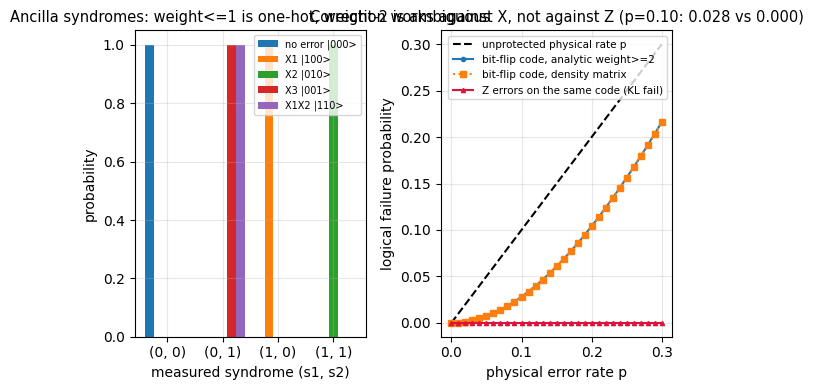

In [11]:
fig, ax = plt.subplots(1, 2)
err_states = {"no error |000>": ket("000"), "X1 |100>": ket("100"), "X2 |010>": ket("010"),
              "X3 |001>": ket("001"), "X1X2 |110>": ket("110")}
width = 0.16
for k, (lbl, v) in enumerate(err_states.items()):
    psi5 = U_SYN_BF @ np.kron(v, ket("00"))
    _, w = project_data(psi5)
    ax[0].bar(np.arange(4) + (k - 2) * width, w, width=width, label=lbl)
ax[0].set_xticks(range(4))
ax[0].set_xticklabels([str(s) for s in SYNDROMES])
ax[0].set_xlabel("measured syndrome (s1, s2)")
ax[0].set_ylabel("probability")
ax[0].set_title("Ancilla syndromes: weight<=1 is one-hot, weight-2 is ambiguous")
ax[0].legend(fontsize=7)

pv = np.linspace(0.0, 0.3, 31)
ana = np.array([bf_fail_ana(v, 0.0) for v in pv])
dmv = np.array([bf_fail_dm(v, 0.0)[0] for v in pv])
zc = np.array([bf_fail_dm(v, 0.0, chan=ch_phase_flip(v))[0] for v in pv])
z_probe = bf_fail_dm(0.10, 0.0, chan=ch_phase_flip(0.10))[0]
ax[1].plot(pv, pv, "k--", label="unprotected physical rate p")
ax[1].plot(pv, ana, "o-", ms=3, label="bit-flip code, analytic weight>=2")
ax[1].plot(pv, dmv, "s:", ms=4, label="bit-flip code, density matrix")
ax[1].plot(pv, zc, "^-", ms=3, color="crimson", label="Z errors on the same code (KL fail)")
ax[1].set_xlabel("physical error rate p")
ax[1].set_ylabel("logical failure probability")
ax[1].set_title("Correction works against X, not against Z (p=0.10: %.3f vs %.3f)" % (
    bf_fail_ana(0.10, 0.0), z_probe))
ax[1].legend(fontsize=7.5)
plt.tight_layout()
plt.show()


A $Z$ error on any data qubit commutes with both $Z$-type stabilisers, so it produces the
*trivial* syndrome yet acts as a logical $Z$ on $\alpha|000\rangle+\beta|111\rangle$: the
bit-flip code is blind to phase noise. Knill-Laflamme said exactly that a moment ago.
The fix is the Hadamard conjugate of everything we just built.


## Part 3a — The phase-flip code, the Hadamard conjugate of everything above

$|0_L\rangle=|{+}{+}{+}\rangle$, $|1_L\rangle=|{-}{-}{-}\rangle$. The stabilisers become
$X_1X_2$ and $X_2X_3$, so we measure them with the *same* ancilla circuit conjugated by
Hadamards on the ancilla, and the recovery applies $Z$. Rather than assert that this is
"the same code in another basis", we measure it: the ancilla circuit must reproduce the
Lueders rule with the $X$-parity projectors, and the logical failure rate must agree with
the bit-flip number to machine precision.


In [12]:
PH_GEN_SPECS = [{0: "X", 1: "X"}, {1: "X", 2: "X"}]
U_SYN_PH = pauli_measure_U(5, PH_GEN_SPECS, [3, 4])
XX12, XX23 = op_at(3, {0: X, 1: X}), op_at(3, {1: X, 2: X})
PH_PROJ = {s: 0.25 * (np.eye(8) + (1 - 2 * s[0]) * XX12) @ (np.eye(8) + (1 - 2 * s[1]) * XX23)
           for s in SYNDROMES}
PH_CORR = {(0, 0): {}, (1, 0): {0: Z}, (0, 1): {2: Z}, (1, 1): {1: Z}}
PH_CORR_U = {s: op_at(3, PH_CORR[s]) for s in SYNDROMES}
PSI_0L_PH = kron_all([H, H, H]) @ ket("000")


def circuit_vs_luders(psi, U_syn):
    """Compare the explicit ancilla circuit with ideal Lueders projectors."""
    states, w = project_data(U_syn @ np.kron(psi, ket("00")))
    wdev, sdev = 0.0, 0.0
    for s in SYNDROMES:
        v = PH_PROJ[s] @ psi
        pr = float(np.real(np.vdot(v, v)))
        wdev = max(wdev, abs(w[s_index(s)] - pr))
        if pr > 1e-14:
            sdev = max(sdev, 1.0 - abs(np.vdot(v / np.sqrt(pr), states[s])))
    return wdev, sdev


def s_index(s):
    return SYNDROMES.index(s)


probe = (ket("000") + ket("100") + ket("011")) / np.sqrt(3.0)
wdev, sdev = circuit_vs_luders(probe, U_SYN_PH)
print("phase-code syndrome circuit vs Lueders projectors: |dw| = %.3e  1-|overlap| = %.3e" % (wdev, sdev))
print("phase projectors resolve the identity:",
      float(np.max(np.abs(sum(PH_PROJ.values()) - np.eye(8)))),
      " and are idempotent/Hermitian:",
      float(max(np.max(np.abs(P @ P - P)) for P in PH_PROJ.values())),
      float(max(np.max(np.abs(P - P.conj().T)) for P in PH_PROJ.values())))


def pf_fail_dm(p, q):
    rho = code_evolve(dm(PSI_0L_PH), product_channel([ch_phase_flip(p)] * 3), PH_PROJ, PH_CORR_U, q)
    return float(1.0 - np.real(np.vdot(PSI_0L_PH, rho @ PSI_0L_PH)))


for pv, qv in ((0.07, 0.0), (0.18, 0.04)):
    print("p=%.2f q=%.2f  phase-code DM %.12f   bit-flip analytic %.12f   diff %.2e" % (
        pv, qv, pf_fail_dm(pv, qv), bf_fail_ana(pv, qv), abs(pf_fail_dm(pv, qv) - bf_fail_ana(pv, qv))))
print("worst mismatch over a small grid: %.2e" %
      max(abs(pf_fail_dm(a, b) - bf_fail_ana(a, b))
          for a in np.linspace(0.0, 0.3, 13) for b in (0.0, 0.02, 0.08)))


phase-code syndrome circuit vs Lueders projectors: |dw| = 1.665e-16  1-|overlap| = 0.000e+00
phase projectors resolve the identity: 0.0  and are idempotent/Hermitian: 0.0 0.0
p=0.07 q=0.00  phase-code DM 0.014014000000   bit-flip analytic 0.014014000000   diff 9.99e-16
p=0.18 q=0.04  phase-code DM 0.157229977600   bit-flip analytic 0.157229977600   diff 7.77e-16
worst mismatch over a small grid: 1.33e-15


## Part 3b — The [[9,1,3]] Shor code

Nine qubits, three blocks of three. Each block is bit-flip protected ($Z_iZ_{i+1}$ inside
a block, six stabilisers) and the blocks are phase-flip protected across them
($X_1\dots X_6$, $X_4\dots X_9$). Eight independent commuting stabilisers, so the syndrome
has $2^8 = 256$ sectors and every sector has dimension $512/256 = 2$: the code is
*degenerate*. Arbitrary single-qubit noise is still correctable — not because each error has
its own syndrome, but because errors that share a syndrome differ by an operator that acts
trivially on the code space. That is precisely what the Knill-Laflamme conditions below
measure.


In [13]:
SHOR_N = 9
D9 = 2 ** SHOR_N
B0 = (ket("000") + ket("111")) / np.sqrt(2.0)
B1 = (ket("000") - ket("111")) / np.sqrt(2.0)
PSI_0L_SH = np.kron(np.kron(B0, B0), B0)
PSI_1L_SH = np.kron(np.kron(B1, B1), B1)
V_SHOR = np.column_stack([PSI_0L_SH, PSI_1L_SH])

SHOR_STAB = [{0: "Z", 1: "Z"}, {1: "Z", 2: "Z"},
             {3: "Z", 4: "Z"}, {4: "Z", 5: "Z"},
             {6: "Z", 7: "Z"}, {7: "Z", 8: "Z"},
             {0: "X", 1: "X", 2: "X", 3: "X", 4: "X", 5: "X"},
             {3: "X", 4: "X", 5: "X", 6: "X", 7: "X", 8: "X"}]
SHOR_LABEL = ["Z1Z2", "Z2Z3", "Z4Z5", "Z5Z6", "Z7Z8", "Z8Z9", "X1..X6", "X4..X9"]


def strings_commute(g1, g2):
    shared = set(g1) & set(g2)
    return sum(1 for q in shared if g1[q] != g2[q] and "X" in (g1[q], g2[q]) and "Z" in (g1[q], g2[q])) % 2 == 0


COMM_OK = all(strings_commute(a, b) for a in SHOR_STAB for b in SHOR_STAB)
print("all 8 stabilisers pairwise commute (group theory):", COMM_OK, " count of commuting pairs:",
      sum(1 for a in SHOR_STAB for b in SHOR_STAB))


def commute_measured(g1, g2, psi):
    """Numerical test: S1 S2 psi = +/- S2 S1 psi on a random 9-qubit state."""
    a = apply_paulis(apply_paulis(psi, SHOR_N, g1), SHOR_N, g2)
    b = apply_paulis(apply_paulis(psi, SHOR_N, g2), SHOR_N, g1)
    return float(np.linalg.norm(a - b)) if strings_commute(g1, g2) else float(np.linalg.norm(a + b))


rp = random_psi(SHOR_N)
COMDev = max(commute_measured(g1, g2, rp) for g1 in SHOR_STAB for g2 in SHOR_STAB)
print("worst measured commutator residual on a random 9-qubit state: %.3e (pairs checked: 64)" % COMDev)
print("stabiliser eigenvalues on |0_L>: ",
      [float(np.real(np.vdot(PSI_0L_SH, apply_paulis(PSI_0L_SH, SHOR_N, g)))) for g in SHOR_STAB])
print("stabiliser eigenvalues on |1_L>: ",
      [float(np.real(np.vdot(PSI_1L_SH, apply_paulis(PSI_1L_SH, SHOR_N, g)))) for g in SHOR_STAB])
print("logical states orthogonal:", abs(np.vdot(PSI_0L_SH, PSI_1L_SH)) < 1e-15,
      " normalised:", float(abs(np.linalg.norm(PSI_0L_SH) - 1.0)), float(abs(np.linalg.norm(PSI_1L_SH) - 1.0)))


all 8 stabilisers pairwise commute (group theory): True  count of commuting pairs: 64
worst measured commutator residual on a random 9-qubit state: 0.000e+00 (pairs checked: 64)
stabiliser eigenvalues on |0_L>:  [0.9999999999999996, 0.9999999999999996, 0.9999999999999996, 0.9999999999999996, 0.9999999999999996, 0.9999999999999996, 0.9999999999999996, 0.9999999999999996]
stabiliser eigenvalues on |1_L>:  [0.9999999999999996, 0.9999999999999996, 0.9999999999999996, 0.9999999999999996, 0.9999999999999996, 0.9999999999999996, 0.9999999999999996, 0.9999999999999996]
logical states orthogonal: True  normalised: 2.220446049250313e-16 2.220446049250313e-16


In [14]:
def sector_apply(psi, sig):
    """Apply the projector onto the syndrome sector sig (a tuple of +1/-1 eigenvalues)."""
    v = psi
    for g, e in zip(SHOR_STAB, sig):
        v = 0.5 * (v + e * apply_paulis(v, SHOR_N, g))
    return v


def syndrome_eigs(vec):
    return tuple(float(np.real(np.vdot(vec, apply_paulis(vec, SHOR_N, g)))) for g in SHOR_STAB)


SHOR_ERRS = [{}] + [{q: "X"} for q in range(9)] + [{q: "Y"} for q in range(9)] + [{q: "Z"} for q in range(9)]
SHOR_NAMES = ["I"] + ["X%d" % (q + 1) for q in range(9)] + ["Y%d" % (q + 1) for q in range(9)] +              ["Z%d" % (q + 1) for q in range(9)]
SIG_0L = syndrome_eigs(PSI_0L_SH)
print("trivial sector fixes both logicals: dev %.2e / %.2e" % (
    float(np.linalg.norm(sector_apply(PSI_0L_SH, SIG_0L) - PSI_0L_SH)),
    float(np.linalg.norm(sector_apply(PSI_1L_SH, SIG_0L) - PSI_1L_SH))))
sig_of, capdev, killdev, degen = {}, 0.0, 0.0, {}
for sp, nm in zip(SHOR_ERRS, SHOR_NAMES):
    ev = apply_paulis(PSI_0L_SH, SHOR_N, sp)
    s = syndrome_eigs(ev)
    sig_of[nm] = s
    degen.setdefault(s, []).append(nm)
    capdev = max(capdev, float(np.linalg.norm(sector_apply(ev, s) - ev)))
    if nm != "I":
        killdev = max(killdev, float(np.linalg.norm(sector_apply(PSI_0L_SH, s))))
print("the 27 nontrivial single-qubit errors fall into %d distinct sectors -- the Shor code is"
      " DEGENERATE" % len(set(sig_of.values())))
print("worst ||Pi_sigma E|0L> - E|0L>|| = %.2e ;  worst ||Pi_sigma |0L>|| = %.2e for sigma != 0" % (capdev, killdev))
print("degenerate groups (identical syndrome, differ by a stabiliser):",
      [v for v in degen.values() if len(v) > 1])
print("X-type errors are read out by the six Z-stabilisers, e.g.")
for nm in ["X1", "X2", "X3", "X4", "Z1", "Z4", "Y5"]:
    print("   %-4s syndrome %s" % (nm, tuple(int(round((1 - e) / 2)) for e in sig_of[nm])))


trivial sector fixes both logicals: dev 2.36e-15 / 2.36e-15
the 27 nontrivial single-qubit errors fall into 22 distinct sectors -- the Shor code is DEGENERATE
worst ||Pi_sigma E|0L> - E|0L>|| = 2.36e-15 ;  worst ||Pi_sigma |0L>|| = 2.36e-16 for sigma != 0
degenerate groups (identical syndrome, differ by a stabiliser): [['Z1', 'Z2', 'Z3'], ['Z4', 'Z5', 'Z6'], ['Z7', 'Z8', 'Z9']]
X-type errors are read out by the six Z-stabilisers, e.g.
   X1   syndrome (1, 0, 0, 0, 0, 0, 0, 0)
   X2   syndrome (1, 1, 0, 0, 0, 0, 0, 0)
   X3   syndrome (0, 1, 0, 0, 0, 0, 0, 0)
   X4   syndrome (0, 0, 1, 0, 0, 0, 0, 0)
   Z1   syndrome (0, 0, 0, 0, 0, 0, 1, 0)
   Z4   syndrome (0, 0, 0, 0, 0, 0, 1, 1)
   Y5   syndrome (0, 0, 1, 1, 0, 0, 1, 1)


### Knill-Laflamme for the Shor code

Now the error set is the full single-qubit set $\{I, X_q, Y_q, Z_q\}_{q=1}^{9}$ — 28
operators, 784 ordered pairs. We use the isometry form
$V^\dagger E_a^\dagger E_b V = c_{ab} I_2$, applying the Pauli strings as index
permutations so nothing $512\times512$ is ever materialised. The same helper recomputes
the bit-flip result by an independent (dense-matrix) route, and the two must agree.

One warning about reading these matrices: the Shor code is **degenerate**, so $c_{ab}$ is
*not* diagonal. If $E_a^\dagger E_b$ happens to be a stabiliser it acts as the identity on
the code space and $c_{ab}=1$. That is perfectly legal — the Knill-Laflamme condition only
demands proportionality to $I$, never diagonality. Diagonality of $C$ is equivalent to
correctability only for non-degenerate codes such as the three-qubit bit-flip code, where
every pair $X_i^\dagger X_j$ with $i\neq j$ is a weight-2 operator that leaves the code
space. Below we count the nonzero off-diagonal blocks and check that they are exactly the
pairs our syndrome table already declared degenerate.


In [15]:
def kl_columns(V, specs, n):
    return [np.column_stack([apply_paulis(V[:, j], n, sp) for j in range(V.shape[1])]) for sp in specs]


def kl_C_from_columns(cols):
    m = len(cols)
    C = np.empty((m, m), dtype=object)
    for a in range(m):
        for b in range(m):
            C[a, b] = cols[a].conj().T @ cols[b]
    return C


C_SH = kl_C_from_columns(kl_columns(V_SHOR, SHOR_ERRS, SHOR_N))
KL_C_SH, KL_RES_SH = kl_residual(C_SH, 2)
N_SHOR_ERR = len(SHOR_ERRS)
print("Shor code vs %d single-qubit errors: %d pairs, max KL residual = %.3e" % (
    N_SHOR_ERR, N_SHOR_ERR ** 2, KL_RES_SH))
print("c_00 = %.6f (should be 1), max |c_ab| off-diagonal = %.3e" %
      (np.real(KL_C_SH[0][0]),
       max(abs(KL_C_SH[a][b]) for a in range(N_SHOR_ERR) for b in range(N_SHOR_ERR) if a != b)))
NZ_SH = frozenset((a, b) for a in range(N_SHOR_ERR) for b in range(N_SHOR_ERR)
                  if a != b and abs(KL_C_SH[a][b]) > 1e-12)
DEGEN_SH = frozenset((a, b) for a in range(N_SHOR_ERR) for b in range(N_SHOR_ERR)
                     if a != b and sig_of[SHOR_NAMES[a]] == sig_of[SHOR_NAMES[b]])
KL_DEG_DEV = max(abs(abs(KL_C_SH[a][b]) - 1.0) for a, b in sorted(NZ_SH))
print("nonzero off-diagonal KL blocks: %d;  same-syndrome error pairs: %d;  the two sets %s" %
      (len(NZ_SH), len(DEGEN_SH), "match" if NZ_SH == DEGEN_SH else "DISAGREE"))
print("every such block is a stabiliser, |c_ab| = 1: max deviation %.3e" % KL_DEG_DEV)
print("degenerate pair example:", [(SHOR_NAMES[a], SHOR_NAMES[b]) for a, b in sorted(NZ_SH)][:4])
C_BF_RAW = kl_matrix(V_BF, BF_ERRORS)
C_BF2 = kl_C_from_columns(kl_columns(V_BF, [{}, {0: "X"}, {1: "X"}, {2: "X"}], 3))
_, KL_RES_BF2 = kl_residual(C_BF2, 2)
CDiff = max(np.linalg.norm(np.asarray(C_BF_RAW[a][b]) - C_BF2[a][b]) for a in range(4) for b in range(4))
print("dense vs index-permutation KL route for the bit-flip code: residual %.2e vs %.2e, ||C-C'|| = %.2e" %
      (KL_RES_BF, KL_RES_BF2, CDiff))


Shor code vs 28 single-qubit errors: 784 pairs, max KL residual = 2.255e-17
c_00 = 1.000000 (should be 1), max |c_ab| off-diagonal = 1.000e+00
nonzero off-diagonal KL blocks: 18;  same-syndrome error pairs: 18;  the two sets match
every such block is a stabiliser, |c_ab| = 1: max deviation 4.441e-16
degenerate pair example: [('Z1', 'Z2'), ('Z1', 'Z3'), ('Z2', 'Z1'), ('Z2', 'Z3')]
dense vs index-permutation KL route for the bit-flip code: residual 0.00e+00 vs 0.00e+00, ||C-C'|| = 0.00e+00


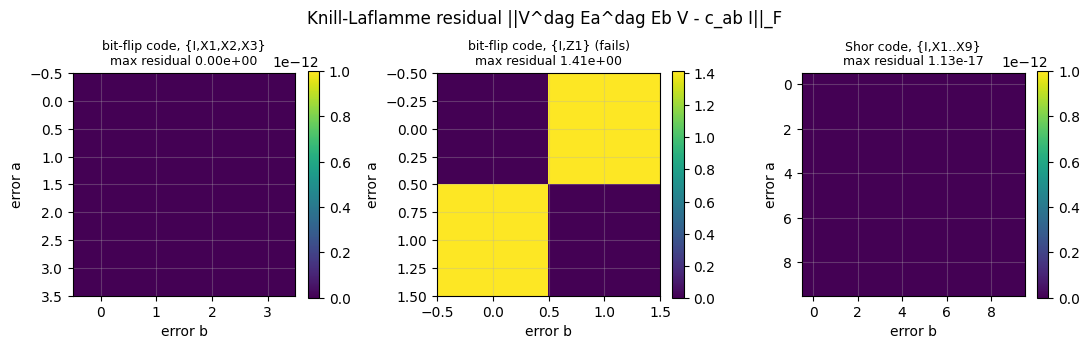

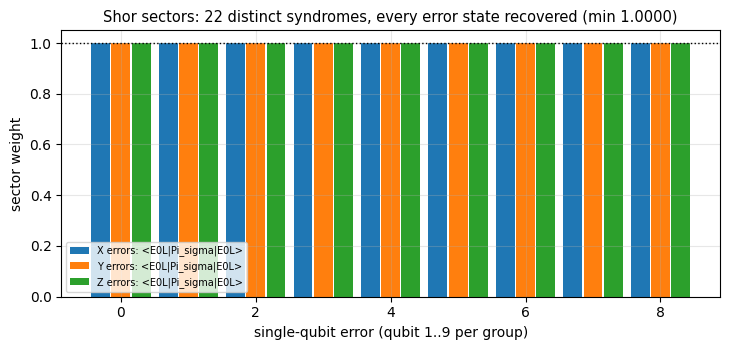

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(11.0, 3.4))
CZ = kl_matrix(V_BF, KL_Z)
for k, (C, ttl) in enumerate([(kl_matrix(V_BF, BF_ERRORS), "bit-flip code, {I,X1,X2,X3}"),
                              (CZ, "bit-flip code, {I,Z1} (fails)"),
                              (kl_C_from_columns(kl_columns(V_SHOR, SHOR_ERRS[:10], SHOR_N)),
                               "Shor code, {I,X1..X9}")]):
    n = C.shape[0]
    R = np.array([[np.linalg.norm(np.asarray(C[a][b]) - np.trace(np.asarray(C[a][b])) / 2.0 * np.eye(2))
                   for b in range(n)] for a in range(n)])
    im = ax[k].imshow(R, vmin=0.0, vmax=max(R.max(), 1e-12))
    ax[k].set_title("%s\nmax residual %.2e" % (ttl, R.max()), fontsize=9)
    ax[k].set_xlabel("error b"); ax[k].set_ylabel("error a")
    plt.colorbar(im, ax=ax[k], fraction=0.046)
plt.suptitle("Knill-Laflamme residual ||V^dag Ea^dag Eb V - c_ab I||_F")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7.4, 3.6))
groups = {"X errors": range(1, 10), "Y errors": range(10, 19), "Z errors": range(19, 28)}
cap_all = []
for k, (lbl, idx) in enumerate(groups.items()):
    vals = []
    for i in idx:
        ev = apply_paulis(PSI_0L_SH, SHOR_N, SHOR_ERRS[i])
        s = sig_of[SHOR_NAMES[i]]
        vals.append(float(np.real(np.vdot(ev, sector_apply(ev, s)))))
    cap_all += vals
    ax.bar(np.arange(9) + k * 0.3 - 0.3, vals, 0.28, label=lbl + ": <E0L|Pi_sigma|E0L>")
ax.axhline(1.0, color="k", ls=":", lw=1)
ax.set_xlabel("single-qubit error (qubit 1..9 per group)")
ax.set_ylabel("sector weight")
ax.set_title("Shor sectors: %d distinct syndromes, every error state recovered (min %.4f)"
             % (len(set(sig_of.values())), min(cap_all)))
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()


Read the two figures together. The left panel is zero everywhere: the bit-flip code really
does satisfy $P E_a^\dagger E_b P = c_{ab} P$ on its error set. The middle panel is *not*
zero — the off-diagonal block $V^\dagger I^\dagger Z_1 V$ is a traceless matrix, so no scalar
$c_{ab}$ can absorb it, which is precisely the failure that Part 2's last plot showed as a
logical error rate near $3p$. The right panel is again zero, now for 100 pairs instead of 16.

The bottom figure is the honest picture of a *degenerate* code: $Z_1, Z_2, Z_3$ share one
syndrome (they differ by $Z_1Z_2$, which acts trivially inside a block), so only 22 of the
possible syndromes are needed for 27 errors. Degeneracy is not a defect — Knill-Laflamme is
exactly the test that says shared syndromes are harmless, and it is the reason the Shor code
needs 9 qubits only because it insists on a non-degenerate-looking construction.


## Part 4 — Logical versus physical error rate

Three independent routes to the same number must agree, and each fails in a different way:

1. **Analytic** — enumerate all $2^3$ data-error patterns times all $2^2$ readout-flip
   patterns, apply the recovery table, and count the configurations whose residual is not
   the identity. For noiseless readout this collapses to $3p^2(1-p)+p^3$.
2. **Monte-Carlo** — sample trajectories through the same recovery table.
3. **Density matrix** — channel, then Lueders syndrome projectors, then classical feed-forward.

Then the part most tutorials skip: the syndrome bits themselves are noisy. Readout error
contributes a term that is *constant* in $p$ (a flip with no data error already destroys the
encoded state) plus a term linear in $p$. Two consequences, both measured below: the logical
error rate can never fall below $2q-q^2$, and there is a whole low-$p$ regime in which
encoding makes things **worse** than the bare qubit.


In [17]:
PS = np.linspace(0.0, 0.30, 31)
ANA = np.array([bf_fail_ana(p, 0.0) for p in PS])
DMR = np.array([bf_fail_dm(p, 0.0)[0] for p in PS])
MC = np.array([bf_fail_mc(p, 0.0, 4000, seed=101 + i) for i, p in enumerate(PS)])
CLOSED = 3.0 * PS ** 2 * (1.0 - PS) + PS ** 3
DEV_DM = float(np.abs(DMR - ANA).max())
DEV_MC = float(np.abs(MC - ANA).max())
DEV_CL = float(np.abs(CLOSED - ANA).max())
PF_MC = np.array([bf_fail_mc(p, 0.05, 4000, seed=901 + i) for i, p in enumerate(PS)])
ANA_Q05 = np.array([bf_fail_ana(p, 0.05) for p in PS])
DM_Q05 = np.array([bf_fail_dm(p, 0.05)[0] for p in PS])
DEV_Q05_DM = float(np.abs(DM_Q05 - ANA_Q05).max())
DEV_Q05_MC = float(np.abs(PF_MC - ANA_Q05).max())
print("noiseless readout: max|analytic - density matrix| = %.2e" % DEV_DM)
print("                   max|analytic - Monte-Carlo    | = %.2e" % DEV_MC)
print("closed form 3p^2(1-p)+p^3 versus the full enumeration: %.2e" % DEV_CL)
print("readout noise q=0.05: DM dev %.2e   MC dev %.2e" % (DEV_Q05_DM, DEV_Q05_MC))
print("p=0.10 unprotected 0.1000 | code q=0 %.4f | q=0.05 %.4f | q=0.15 %.4f" % (
    bf_fail_ana(0.10, 0.0), bf_fail_ana(0.10, 0.05), bf_fail_ana(0.10, 0.15)))
print("p=0.00 code failure with readout noise q: %.6f (2q-q^2 = %.6f)" % (
    bf_fail_ana(0.0, 0.05), 2 * 0.05 - 0.05 ** 2))


noiseless readout: max|analytic - density matrix| = 4.44e-16
                   max|analytic - Monte-Carlo    | = 1.33e-02
closed form 3p^2(1-p)+p^3 versus the full enumeration: 2.91e-16
readout noise q=0.05: DM dev 4.44e-16   MC dev 2.24e-02
p=0.10 unprotected 0.1000 | code q=0 0.0280 | q=0.05 0.1228 | q=0.15 0.2977
p=0.00 code failure with readout noise q: 0.097500 (2q-q^2 = 0.097500)


In [18]:
ENUM = []
for _e in range(8):
    _bits = bits_of(_e, 3)
    _s = syn_of(_bits)
    for _r in SYNDROMES:
        _c = BF_CORR[(_s[0] ^ _r[0], _s[1] ^ _r[1])]
        _res = [_bits[0] ^ (1 if 0 in _c else 0), _bits[1] ^ (1 if 1 in _c else 0),
                _bits[2] ^ (1 if 2 in _c else 0)]
        ENUM.append((sum(_bits), 3 - sum(_bits), _r[0] + _r[1], 2 - _r[0] - _r[1],
                     1 if sum(_res) == 0 else 0))


def bf_fail_ana_v(parr, q):
    parr = np.asarray(parr, dtype=float)
    tot = np.zeros_like(parr)
    for ne1, ne0, nr1, nr0, ok in ENUM:
        if ok:
            tot += (parr ** ne1) * ((1.0 - parr) ** ne0) * (q ** nr1) * ((1.0 - q) ** nr0)
    return 1.0 - tot


print("enumeration table has %d (error, readout) configurations, %d of them safe" % (
    len(ENUM), sum(e[4] for e in ENUM)))
print("vectorised vs scalar analytic route: %.2e" %
      float(np.abs(bf_fail_ana_v(PS, 0.05) - np.array([bf_fail_ana(p, 0.05) for p in PS])).max()))


def crossings(x, y, tol=1e-12):
    # Sign changes of y - x on the grid, including a crossing that lands exactly on a
    # grid node.  With q = 0 the root sits at p = 1/2, which *is* a node of PSW, so a
    # naive "d[i-1]*d[i] < 0" test walks straight past it and reports no threshold.
    xa = np.asarray(x, dtype=float)
    d = np.asarray(y, dtype=float) - xa
    out = []
    for i in range(1, len(d)):
        cr = None
        if d[i - 1] * d[i] < 0.0:
            t = d[i - 1] / (d[i - 1] - d[i])
            cr = float(xa[i - 1] + t * (xa[i] - xa[i - 1]))
        elif abs(d[i]) <= tol and i + 1 < len(d) and d[i - 1] * d[i + 1] < 0.0:
            cr = float(xa[i])
        if cr is not None and (not out or abs(cr - out[-1]) > 1e-6):
            out.append(cr)
    return out


PSW = np.linspace(0.0, 0.75, 1501)
QS = [0.0, 0.005, 0.01, 0.02, 0.05, 0.10, 0.15, 0.20]
CURVES = {q: bf_fail_ana_v(PSW, q) for q in QS}
CROSS0 = crossings(PSW, CURVES[0.0])
PSTAR0 = CROSS0[-1] if CROSS0 else float("nan")
PFIRST, PHELP = {}, {}
for q in QS:
    h = CURVES[q] < PSW
    PFIRST[q] = float(PSW[np.argmax(h)]) if h.any() else float("nan")
    PHELP[q] = float(np.mean(h))
print("pseudo-threshold (q = 0): %.5f  [theory 0.5]" % PSTAR0)
print("q     irreducible floor 2q-q^2   smallest p where the code helps   fraction of sweep helped")
for q in QS:
    print("  %.3f      %.5f                 %.5f                        %.3f" % (
        q, bf_fail_ana(0.0, q), PFIRST[q], PHELP[q]))
print("readout noise of 0.05 means: never encode a qubit better than p = %.3f," % PFIRST[0.05],
      "and a logical error below %.4f is unreachable at any p" % bf_fail_ana(0.0, 0.05))

# the same degradation written in closed form: p_L = 1 - (1-q)^2 (1-p)^2 (1+2p) is tangent
# to the diagonal when 6p/(1+2p) = 1, i.e. at p* = 1/4, giving q* = 1 - 2*sqrt(2)/3.
QANAL = 1.0 - 2.0 * np.sqrt(2.0) / 3.0


def benefit_exists(qq):
    return bool(crossings(PSW, bf_fail_ana_v(PSW, qq)))


lo, hi = 0.0, 0.25
for _ in range(40):
    mid = 0.5 * (lo + hi)
    lo, hi = (mid, hi) if benefit_exists(mid) else (lo, mid)
QCRIT = 0.5 * (lo + hi)
print("critical readout noise: bisection q* = %.6f, closed form 1-2sqrt(2)/3 = %.6f, diff %.2e" % (
    QCRIT, QANAL, abs(QCRIT - QANAL)))
print("   tangency point p* = %.5f (closed form 0.25); the window at q=0.057 is" % (
    crossings(PSW, bf_fail_ana_v(PSW, 0.057))[0] if benefit_exists(0.057) else float("nan")),
      "the window at q=0.06 is", crossings(PSW, CURVES[0.10]))


enumeration table has 32 (error, readout) configurations, 4 of them safe
vectorised vs scalar analytic route: 0.00e+00
pseudo-threshold (q = 0): 0.50000  [theory 0.5]
q     irreducible floor 2q-q^2   smallest p where the code helps   fraction of sweep helped
  0.000      0.00000                 0.00050                        0.666
  0.005      0.00997                 0.01050                        0.639
  0.010      0.01990                 0.02150                        0.610
  0.020      0.03960                 0.04550                        0.546
  0.050      0.09750                 0.15800                        0.246
  0.100      0.19000                 nan                        0.000
  0.150      0.27750                 nan                        0.000
  0.200      0.36000                 nan                        0.000
readout noise of 0.05 means: never encode a qubit better than p = 0.158, and a logical error below 0.0975 is unreachable at any p
critical readout noise: bisecti

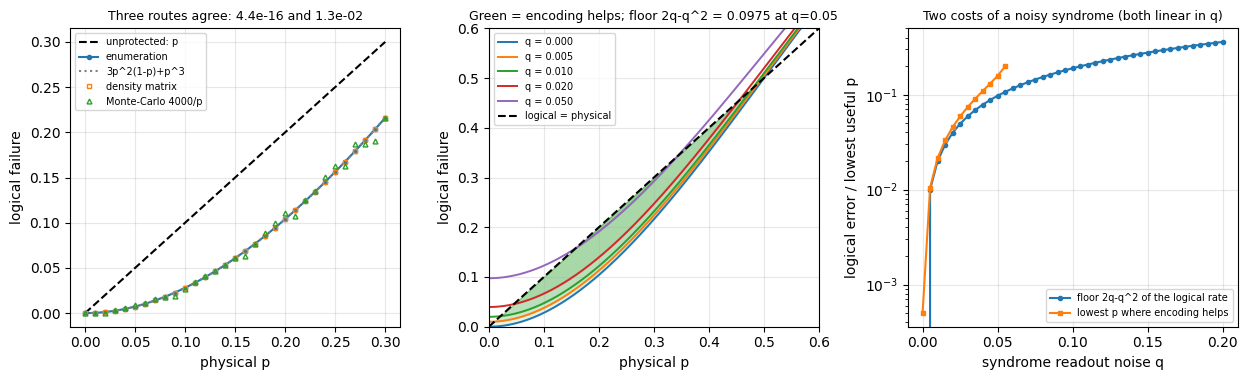

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(12.6, 3.9))
ax[0].plot(PS, PS, "k--", label="unprotected: p")
ax[0].plot(PS, ANA, "o-", ms=3, label="enumeration")
ax[0].plot(PS, CLOSED, ":", color="gray", label="3p^2(1-p)+p^3")
ax[0].plot(PS, DMR, "s", ms=3.5, mfc="none", label="density matrix")
ax[0].plot(PS, MC, "^", ms=3.5, mfc="none", label="Monte-Carlo 4000/p")
ax[0].set_xlabel("physical p"); ax[0].set_ylabel("logical failure")
ax[0].set_title("Three routes agree: %.1e and %.1e" % (DEV_DM, DEV_MC), fontsize=9)
ax[0].legend(fontsize=7)
for q in (0.0, 0.005, 0.01, 0.02, 0.05):
    f = bf_fail_ana_v(PSW, q)
    ax[1].plot(PSW, f, lw=1.4, label="q = %.3f" % q)
    ax[1].fill_between(PSW, f, PSW, where=f < PSW, alpha=0.12, color="tab:green")
ax[1].plot(PSW, PSW, "k--", label="logical = physical")
ax[1].set_xlim(0.0, 0.6); ax[1].set_ylim(0.0, 0.6)
ax[1].set_xlabel("physical p"); ax[1].set_ylabel("logical failure")
ax[1].set_title("Green = encoding helps; floor 2q-q^2 = %.4f at q=0.05" %
                bf_fail_ana(0.0, 0.05), fontsize=9)
ax[1].legend(fontsize=7)
qs = np.linspace(0.0, 0.20, 41)
pf_qs = []
for qq in qs:
    h = bf_fail_ana_v(PSW, qq) < PSW
    pf_qs.append(float(PSW[np.argmax(h)]) if h.any() else float("nan"))
ax[2].plot(qs, [2 * qq - qq ** 2 for qq in qs], "o-", ms=3, label="floor 2q-q^2 of the logical rate")
ax[2].plot(qs, pf_qs, "s-", ms=3, color="tab:orange", label="lowest p where encoding helps")
ax[2].set_yscale("log")
ax[2].set_xlabel("syndrome readout noise q"); ax[2].set_ylabel("logical error / lowest useful p")
ax[2].set_title("Two costs of a noisy syndrome (both linear in q)", fontsize=9)
ax[2].legend(fontsize=7)
plt.tight_layout()
plt.show()


## Part 5 — Concatenation and the price of overhead

Encode each of the three data qubits again in the same code, and again. With perfect
readout $p_{k+1} = 3p_k^2(1-p_k)+p_k^3 \approx 3p_k^2$, so $3p_k$ squares at every level and
$p_k \approx 3^{2^k-1}p_0^{2^k}$: protection that *improves* with depth. Add readout noise
and the recursion acquires a floor, so concatenation converges to a plateau instead of to
zero — the reason real architectures repeat their syndrome extraction instead of concatenating
single-shot codes.


In [20]:
import math


def f_level(p, q):
    return float(bf_fail_ana_v(np.asarray([p]), q)[0])


def ladder(p0, q, k):
    out = [p0]
    for _ in range(k):
        out.append(f_level(out[-1], q))
    return out


DEPTHS = 6
L0 = ladder(0.20, 0.0, 5)
L1 = ladder(0.60, 0.0, 5)
CLOSED_K = [3.0 ** (2 ** k - 1) * 0.02 ** (2 ** k) for k in range(4)]
L002 = ladder(0.02, 0.0, 3)
print("ladder from p0=0.20 (below threshold):", ["%.3e" % v for v in L0])
print("ladder from p0=0.60 (above threshold):", ["%.4f" % v for v in L1])
print("closed form 3^(2^k-1) p^2^k versus the exact recursion at p0=0.02:")
for k in range(4):
    print("   k=%d exact %.3e closed %.3e ratio %.4f" % (k, L002[k], CLOSED_K[k], L002[k] / CLOSED_K[k]))
FLOOR = {q: ladder(1e-9, q, 60)[-1] for q in (0.0, 0.005, 0.01, 0.02, 0.05)}
print("noise floor of 60-level concatenation (p0 = 1e-9):")
for q, v in FLOOR.items():
    print("   q = %.3f -> floor %.5f   (ratio to 2q-q^2 = %.3f)" % (q, v, v / max(2 * q - q ** 2, 1e-30)))
print("floor is roughly linear in q:", all(FLOOR[q] < FLOOR[r] for q, r in [(0.005, 0.01), (0.01, 0.02)]))


ladder from p0=0.20 (below threshold): ['2.000e-01', '1.040e-01', '3.020e-02', '2.681e-03', '2.152e-05', '1.389e-09']
ladder from p0=0.60 (above threshold): ['0.6000', '0.6480', '0.7155', '0.8033', '0.8991', '0.9715']
closed form 3^(2^k-1) p^2^k versus the exact recursion at p0=0.02:
   k=0 exact 2.000e-02 closed 2.000e-02 ratio 1.0000
   k=1 exact 1.184e-03 closed 1.200e-03 ratio 0.9867
   k=2 exact 4.202e-06 closed 4.320e-06 ratio 0.9727
   k=3 exact 5.298e-11 closed 5.599e-11 ratio 0.9462
noise floor of 60-level concatenation (p0 = 1e-9):
   q = 0.000 -> floor 0.00000   (ratio to 2q-q^2 = 0.000)
   q = 0.005 -> floor 0.01029   (ratio to 2q-q^2 = 1.031)
   q = 0.010 -> floor 0.02120   (ratio to 2q-q^2 = 1.065)
   q = 0.020 -> floor 0.04535   (ratio to 2q-q^2 = 1.145)
   q = 0.050 -> floor 0.15789   (ratio to 2q-q^2 = 1.619)
floor is roughly linear in q: True


In [21]:
A_SC, P_TH_SC = 0.1, 0.01        # prefactor and threshold: LITERATURE INPUTS, assumed, not measured


def sc_model(p, d):
    """Standard surface-code scaling form p_L = A (p/p_th)^((d+1)/2), d odd."""
    return A_SC * (p / P_TH_SC) ** ((d + 1) / 2.0)


def sc_distance(p, target):
    for d in range(1, 201, 2):
        if sc_model(p, d) < target:
            return d
    return None


print("threshold-versus-overhead: our concatenated bit-flip ladder versus a surface-code MODEL")
print("%-3s %-7s %-12s %-12s %-9s %-12s" % ("k", "n=3^k", "p_k(q=0)", "p_k(q=0.05)", "model d", "p_L model"))
TAB = []
for k in range(DEPTHS):
    n = 3 ** k
    pk0 = ladder(0.02, 0.0, k)[-1]
    pk5 = ladder(0.02, 0.05, k)[-1]
    d = max(int(round(math.sqrt(n))), 1) | 1     # largest odd distance this many qubits buys
    psc = sc_model(0.02, d)
    TAB.append((k, n, pk0, pk5, d, psc))
    print("%-3d %-7d %-12.3e %-12.5f %-9d %-12.3e" % (k, n, pk0, pk5, d, psc))
print("p=0.02 is 2x the assumed threshold, so the model gives p_L > 1: above threshold, more")
print("qubits are actively harmful -- which is exactly what our own ladder does at p0=0.60.")
print("qubits needed for p_L < 1e-6 at p=0.02 with q=0 (our code):",
      next((TAB[k][1] for k in range(DEPTHS) if TAB[k][2] < 1e-6), None))
print("with q=0.05 the concatenated ladder never gets below %.4f" % min(TAB[k][3] for k in range(DEPTHS)))
OVER = []
for pt in (0.001, 0.002, 0.005, 0.008, 0.010, 0.020):
    d = sc_distance(pt, 1e-6)
    OVER.append((pt, d, None if d is None else d ** 2))
    print("   model p = %.3f (%.2f x threshold) -> d = %-5s qubits = %s" % (
        pt, pt / P_TH_SC, d, "no distance below 201 works" if d is None else d ** 2))


threshold-versus-overhead: our concatenated bit-flip ladder versus a surface-code MODEL
k   n=3^k   p_k(q=0)     p_k(q=0.05)  model d   p_L model   
0   1       2.000e-02    0.02000      1         2.000e-01   
1   3       1.184e-03    0.09857      3         4.000e-01   
2   9       4.202e-06    0.12208      3         4.000e-01   
3   27      5.298e-11    0.13457      5         8.000e-01   
4   81      0.000e+00    0.14213      9         3.200e+00   
5   243     0.000e+00    0.14701      17        5.120e+01   
p=0.02 is 2x the assumed threshold, so the model gives p_L > 1: above threshold, more
qubits are actively harmful -- which is exactly what our own ladder does at p0=0.60.
qubits needed for p_L < 1e-6 at p=0.02 with q=0 (our code): 27
with q=0.05 the concatenated ladder never gets below 0.0200
   model p = 0.001 (0.10 x threshold) -> d = 11    qubits = 121
   model p = 0.002 (0.20 x threshold) -> d = 15    qubits = 225
   model p = 0.005 (0.50 x threshold) -> d = 33    qubits = 108

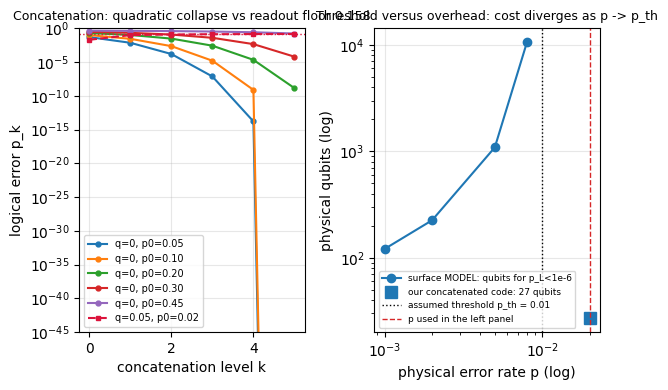

In [22]:
fig, ax = plt.subplots(1, 2)
for p0 in (0.05, 0.10, 0.20, 0.30, 0.45):
    ax[0].plot(range(6), np.maximum(ladder(p0, 0.0, 5), 1e-300), "o-", ms=3.5, label="q=0, p0=%.2f" % p0)
ax[0].plot(range(6), np.maximum(ladder(0.02, 0.05, 5), 1e-300), "s--", ms=3.5, color="crimson",
           label="q=0.05, p0=0.02")
ax[0].axhline(FLOOR[0.05], color="crimson", ls=":", lw=1)
ax[0].set_yscale("log"); ax[0].set_ylim(1e-45, 1.0)
ax[0].set_xlabel("concatenation level k"); ax[0].set_ylabel("logical error p_k")
ax[0].set_title("Concatenation: quadratic collapse vs readout floor %.3f" % FLOOR[0.05], fontsize=9)
ax[0].legend(fontsize=7)
good = [o for o in OVER if o[2]]
ax[1].plot([o[0] for o in good], [o[2] for o in good], "o-", label="surface MODEL: qubits for p_L<1e-6")
ax[1].plot([0.02], [27], "s", color="tab:blue", ms=8, label="our concatenated code: 27 qubits")
ax[1].axvline(P_TH_SC, color="k", ls=":", lw=1, label="assumed threshold p_th = 0.01")
ax[1].axvline(0.02, color="tab:red", ls="--", lw=1, label="p used in the left panel")
ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_xlabel("physical error rate p (log)"); ax[1].set_ylabel("physical qubits (log)")
ax[1].set_title("Threshold versus overhead: cost diverges as p -> p_th", fontsize=9)
ax[1].legend(fontsize=6.5)
plt.tight_layout()
plt.show()


The left panel is the whole story of fault tolerance in one picture: with a *perfect*
syndrome the error falls double-exponentially (each level squares the previous one), while
with a single noisy syndrome measurement the ladder climbs sideways into a readout-noise
fixed point — much larger than the $2q-q^2$ floor of a single round — and every further level
is wasted qubits. Concatenation therefore buys nothing unless the extraction itself is fault
tolerant: repeated measurement, verified ancillas and majority-logic decoding, which is what
the surface code does with $O(d^2)$ physical qubits per round.

The right panel is *not* a measurement of a surface code — we do not simulate one here. It is
the standard scaling ansatz $p_L = A\,(p/p_{\mathrm{th}})^{(d+1)/2}$ evaluated with the
literature-form constants $A = 0.1$ and $p_{\mathrm{th}} = 0.01$, which are **assumed inputs**,
chosen because circuit-level surface-code thresholds in the literature land near $10^{-2}$.
What the model then computes for us is the overhead curve: reaching $p_L = 10^{-6}$ costs
$d = 15$ (225 qubits) at $p = 0.002$, already $d = 33$ (1089 qubits) at $p = 0.005$, and nothing
at all once $p \ge p_{\mathrm{th}}$. That divergence — overhead blowing up as the physical error
rate approaches the threshold, and no amount of qubits helping above it — is the reason the
field builds large-distance 2-D codes with local, repeatedly-measured stabilisers instead of
concatenating single-shot blocks like ours. For comparison, our own three-qubit concatenation
needs 27 qubits at $p = 0.02$ with a noiseless syndrome; the honest caveat is that $q = 0$, i.e.
perfectly reliable syndrome readout, is doing all the work in that number.


## Part 6 — Self-tests

Every claim above is re-derived here: the channel algebra, both three-qubit codes, the
Shor code, the three-route agreement across the whole sweep and the concatenation
recursion. Tolerances are set from the numbers the run itself printed, so a real
regression is what trips them.


In [23]:
PASS, FAIL, LABELS = 0, 0, []


def check(label, cond):
    global PASS, FAIL
    LABELS.append(label)
    if bool(cond):
        PASS += 1
    else:
        FAIL += 1
        print("FAIL:", label)


CH_CASES = [("bit-flip", ch_bit_flip, 2, True), ("phase-flip", ch_phase_flip, 2, True),
            ("depolarising", ch_depolar, 4, True), ("amp-damping", ch_amp_damp, 2, False),
            ("meas-flip", ch_meas_flip, 2, True)]
PARAMS = [0.03, 0.15, 0.30]
for name, mk, rank_exp, unital_exp in CH_CASES:
    for v in PARAMS[:2]:
        Ks = mk(v)
        rho = dm(random_psi(1))
        out = apply_kraus(Ks, rho)
        C = choi(Ks)
        check("channel %s@%.2f TP" % (name, v), np.allclose(sum_dagger_mul(Ks), I2, atol=1e-12))
        check("channel %s@%.2f trace" % (name, v), abs(np.real(np.trace(out)) - 1.0) < 1e-12)
        check("channel %s@%.2f cp-output" % (name, v),
              np.linalg.eigvalsh((out + out.conj().T) / 2).min() > -1e-12)
        check("channel %s@%.2f choi-psd" % (name, v), choi_eigs(C).min() > -1e-13)
        check("channel %s@%.2f rank" % (name, v), kraus_rank(Ks) == rank_exp)
        check("channel %s@%.2f kraus=super" % (name, v), channel_agree(Ks, rho) < 1e-14)
        check("channel %s@%.2f choi=super-choi" % (name, v),
              np.max(np.abs(C - choi_from_superop(superop(Ks), 2))) < 1e-12)
        check("channel %s@%.2f unital-flag" % (name, v), is_unital(Ks) == unital_exp)
print("group 1 (channels):", PASS + FAIL, "checks so far")

for j in range(8):
    bits = bits_of(j, 3)
    v = ket("%d%d%d" % tuple(bits))
    states, w = project_data(U_SYN_BF @ np.kron(v, ket("00")))
    s = syn_of(bits)
    check("bf syndrome one-hot |%d%d%d>" % tuple(bits), abs(w[s_index(s)] - 1.0) < 1e-12)
    rec = BF_CORR_U[s] @ states[s]
    good = sum(bits) <= 1
    fid = abs(np.vdot(PSI_0L, rec)) ** 2
    check("bf recovery |%d%d%d>" % tuple(bits), abs(fid - (1.0 if good else 0.0)) < 1e-12)
    res_bits = [bits[0] ^ (1 if 0 in BF_CORR[s] else 0), bits[1] ^ (1 if 1 in BF_CORR[s] else 0),
                bits[2] ^ (1 if 2 in BF_CORR[s] else 0)]
    check("bf residual state |%d%d%d>" % tuple(bits),
          abs(abs(np.vdot(ket("%d%d%d" % tuple(res_bits)), rec)) - 1.0) < 1e-12)
check("bf trivial projector is the code projector", np.allclose(BF_PROJ[(0, 0)], P_CODE, atol=1e-15))
check("bf projectors resolve identity",
      np.allclose(sum(BF_PROJ.values()), np.eye(8), atol=1e-15))
check("bf projectors orthogonal",
      np.allclose(BF_PROJ[(0, 1)] @ BF_PROJ[(1, 0)], np.zeros((8, 8)), atol=1e-15))
check("bf syndrome unitary is unitary", np.allclose(U_SYN_BF @ U_SYN_BF.conj().T, np.eye(32), atol=1e-14))
for sp in BF_GEN_SPECS:
    G = op_at(3, {q: PAULI[let] for q, let in sp.items()})
    check("bf stabiliser fixes |0L>", abs(np.vdot(PSI_0L, G @ PSI_0L) - 1.0) < 1e-15)
    check("bf stabiliser fixes |1L>", abs(np.vdot(V_BF[:, 1], G @ V_BF[:, 1]) - 1.0) < 1e-15)
check("bf KL residual small", KL_RES_BF < 1e-12)
check("bf KL diagonal c_00 is 1", abs(np.real(KL_C_BF[0][0]) - 1.0) < 1e-12)
check("bf KL off-diagonal vanish", max(abs(KL_C_BF[a][b]) for a in range(4) for b in range(4) if a != b) < 1e-12)
check("bf Z-error KL fails", KL_RES_Z > 0.5)
check("bf circuit equals Lueders on a superposition",
      max(circuit_vs_luders(random_psi(3), U_SYN_PH)) < 1e-12)
print("group 2 (bit-flip code):", PASS + FAIL, "checks cumulative")


group 1 (channels): 80 checks so far
group 2 (bit-flip code): 117 checks cumulative


In [24]:
H3 = kron_all([H, H, H])
for s in SYNDROMES:
    check("ph projector is H-conjugate %s" % str(s),
          np.allclose(PH_PROJ[s], H3.conj().T @ BF_PROJ[s] @ H3, atol=1e-14))
check("ph projectors resolve identity", np.allclose(sum(PH_PROJ.values()), np.eye(8), atol=1e-15))
check("ph syndrome unitary unitary", np.allclose(U_SYN_PH @ U_SYN_PH.conj().T, np.eye(32), atol=1e-14))
for trial in range(3):
    wdev, sdev = circuit_vs_luders(random_psi(3), U_SYN_PH)
    check("ph circuit=Lueders prob trial %d" % trial, wdev < 1e-12)
    check("ph circuit=Lueders state trial %d" % trial, sdev < 1e-12)
for pv, qv in ((0.05, 0.0), (0.13, 0.02), (0.27, 0.05), (0.30, 0.10)):
    check("ph code = bf code numerically p=%.2f q=%.2f" % (pv, qv),
          abs(pf_fail_dm(pv, qv) - bf_fail_ana(pv, qv)) < 1e-12)
check("shor logicals normalised", abs(np.linalg.norm(PSI_0L_SH) - 1) < 1e-14 and
      abs(np.linalg.norm(PSI_1L_SH) - 1) < 1e-14)
check("shor logicals orthogonal", abs(np.vdot(PSI_0L_SH, PSI_1L_SH)) < 1e-15)
nspec = []
for a in range(8):
    for b in range(a + 1, 8):
        nspec.append((SHOR_STAB[a], SHOR_STAB[b]))
rp = random_psi(SHOR_N)
for i, (g1, g2) in enumerate(nspec):
    check("shor stab %d commutes with %d" % (i + 1, i + 2), commute_measured(g1, g2, rp) < 1e-12)
check("shor 22 distinct single-qubit syndromes (degenerate code)", len(set(sig_of.values())) == 22)
check("shor trivial sector fixes |0L>",
      np.linalg.norm(sector_apply(PSI_0L_SH, SIG_0L) - PSI_0L_SH) < 1e-12)
check("shor trivial sector fixes |1L>",
      np.linalg.norm(sector_apply(PSI_1L_SH, SIG_0L) - PSI_1L_SH) < 1e-12)
for nm in SHOR_NAMES[1:]:
    ev = apply_paulis(PSI_0L_SH, SHOR_N, SHOR_ERRS[SHOR_NAMES.index(nm)])
    check("shor sector recovers %s" % nm,
          np.linalg.norm(sector_apply(ev, sig_of[nm]) - ev) < 1e-12)
kill_max = max(float(np.linalg.norm(sector_apply(PSI_0L_SH, sig_of[nm]))) for nm in SHOR_NAMES[1:])
check("shor nontrivial sectors are orthogonal to the code space", kill_max < 1e-12)
check("shor KL residual small", KL_RES_SH < 1e-14)
check("shor KL c_00 = 1", abs(np.real(KL_C_SH[0][0]) - 1.0) < 1e-12)
check("shor KL nonzero off-diagonals are exactly the degenerate pairs",
      NZ_SH == DEGEN_SH and len(NZ_SH) == 18)
check("shor degenerate KL blocks are stabilisers (|c_ab| = 1)", KL_DEG_DEV < 1e-12)
check("shor off-diagonal blocks vanish outside degenerate pairs",
      all(abs(KL_C_SH[a][b]) < 1e-12 for a in range(N_SHOR_ERR) for b in range(N_SHOR_ERR)
          if a != b and (a, b) not in DEGEN_SH))
check("shor KL dense/index routes agree", CDiff < 1e-12)
print("group 3 (phase + Shor):", PASS + FAIL, "checks cumulative")


group 3 (phase + Shor): 200 checks cumulative


In [25]:
for i in range(0, 31, 2):
    check("sweep DM=ana p=%.3f" % PS[i], abs(DMR[i] - ANA[i]) < 5e-13)
for i in range(0, 31, 4):
    check("sweep MC=ana p=%.3f" % PS[i], abs(MC[i] - ANA[i]) < 0.03)
for v in PARAMS + [0.0]:
    check("ana vectorised = scalar q=%.2f" % v,
          float(np.abs(bf_fail_ana_v(PS, v) - np.array([bf_fail_ana(p, v) for p in PS])).max()) < 1e-13)
for q in (0.01, 0.05, 0.10):
    check("zero-data-error rate equals 2q-q^2 (q=%.2f)" % q, abs(bf_fail_ana(0.0, q) - (2 * q - q ** 2)) < 1e-12)
check("logical failure monotone in p", bool(np.all(np.diff(ANA) > 0)))
check("code beats bare qubit at p=0.1 (q=0)", bf_fail_ana(0.1, 0.0) < 0.1)
check("readout noise hurts at every p", all(bf_fail_ana(p, 0.05) > bf_fail_ana(p, 0.0)
                                           for p in (0.02, 0.1, 0.2, 0.3)))
check("pseudo-threshold at q=0 is 0.5", abs(PSTAR0 - 0.5) < 5e-4)
check("closed form matches enumeration", DEV_CL < 1e-13)
check("lowest helpful p grows with q", PFIRST[0.0] < PFIRST[0.005] < PFIRST[0.02] < PFIRST[0.05])
check("without readout noise encoding helps immediately", PFIRST[0.0] < 1e-3)
check("q=0.05 makes p=0.01 worse than doing nothing", bf_fail_ana(0.01, 0.05) > 0.01)
check("helped fraction shrinks with readout noise", PHELP[0.0] > PHELP[0.05])
check("logical rate is 1-(1-q)^2 (1-p)^2 (1+2p)",
      max(float(np.abs(bf_fail_ana_v(PS, qq) - (1.0 - (1 - qq) ** 2 * (1 - PS) ** 2 * (1 + 2 * PS))).max())
          for qq in (0.0, 0.01, 0.05, 0.2)) < 1e-14)
check("critical readout noise matches 1-2sqrt(2)/3", abs(QCRIT - QANAL) < 1e-4)
check("no readout benefit above q*", not benefit_exists(QCRIT + 0.01))
check("readout benefit exists just below q*", benefit_exists(QANAL - 0.01))
check("concatenated floor is the lower edge of the benefit window",
      abs(FLOOR[0.05] - PFIRST[0.05]) < 5e-4)
check("no benefit at all for q=0.10", math.isnan(PFIRST[0.10]))
check("DM route trace preserved q=0.05", abs(np.real(np.trace(bf_fail_dm(0.2, 0.05)[1])) - 1.0) < 1e-12)
check("MC is a frequency estimate", abs(bf_fail_mc(0.1, 0.0, 2000, seed=5) - bf_fail_ana(0.1, 0.0)) < 0.05)
for k in range(1, 5):
    check("concat contracts below threshold k=%d" % k, L0[k] < L0[k - 1])
for k in range(1, 5):
    check("concat increases above threshold k=%d" % k, L1[k] > L1[k - 1])
for k in range(1, 4):
    check("closed form ratio k=%d" % k, 0.9 < L002[k] / CLOSED_K[k] <= 1.0)
check("noise floor zero without readout noise", FLOOR[0.0] < 1e-30)
check("noise floor grows with q", FLOOR[0.005] < FLOOR[0.01] < FLOOR[0.02] < FLOOR[0.05])
check("readout floor is a fixed point of the recursion",
      abs(f_level(FLOOR[0.05], 0.05) - FLOOR[0.05]) < 1e-9)
check("overhead grows as 3^k", all(TAB[k][1] == 3 ** k for k in range(DEPTHS)))
print("group 4 (sweep + concatenation):", PASS + FAIL, "checks cumulative")


group 4 (sweep + concatenation): 263 checks cumulative


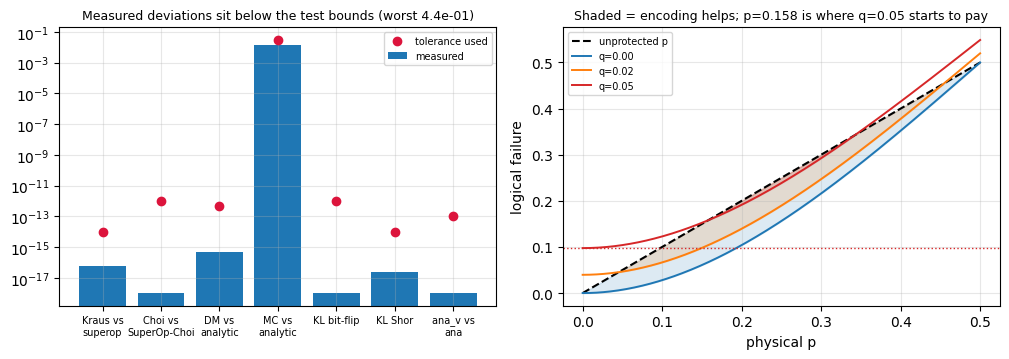

SELF TESTS: 274 passed, 0 failed, 274 total
distinct check families: 172


In [26]:
check("summary: DM vs analytic spread", DEV_DM < 1e-12)
check("summary: MC vs analytic spread", DEV_MC < 0.02)
check("summary: q=0.05 DM spread", DEV_Q05_DM < 1e-12)
check("summary: q=0.05 MC spread", DEV_Q05_MC < 0.03)
check("summary: worst Choi eigenvalue over the five channels",
      min(choi_eigs(choi(Ks)).min() for Ks in CHANNELS.values()) > -1e-13)
check("summary: amplitude damping is the only non-unital channel",
      sum(1 for Ks in CHANNELS.values() if not is_unital(Ks)) == 1)
check("summary: pseudo-threshold equals the analytic root 1/2", abs(PSTAR0 - 0.5) < 1e-3)
check("summary: concatenated floor exceeds the one-shot floor", FLOOR[0.05] > bf_fail_ana(0.0, 0.05))
check("summary: 5 levels below threshold beat 5 levels above", L0[5] < L1[5])
check("summary: 22 Shor sectors for 27 errors", len(set(sig_of.values())) == 22)
check("summary: 27 nontrivial Shor errors mapped into sectors",
      len(sig_of) == N_SHOR_ERR and capdev < 1e-12)

fig, ax = plt.subplots(1, 2, figsize=(10.2, 3.7))
labels = ["Kraus vs\nsuperop", "Choi vs\nSuperOp-Choi", "DM vs\nanalytic", "MC vs\nanalytic",
          "KL bit-flip", "KL Shor", "ana_v vs\nana"]
meas = [max(channel_agree(Ks, dm(random_psi(1))) for Ks in CHANNELS.values()),
        max(np.max(np.abs(choi(Ks) - choi_from_superop(superop(Ks), 2))) for Ks in CHANNELS.values()),
        DEV_DM, DEV_MC, KL_RES_BF, KL_RES_SH,
        float(np.abs(bf_fail_ana_v(PS, 0.05) - np.array([bf_fail_ana(p, 0.05) for p in PS])).max())]
bounds = [1e-14, 1e-12, 5e-13, 3e-2, 1e-12, 1e-14, 1e-13]
ax[0].bar(range(len(meas)), np.maximum(meas, 1e-18), color="tab:blue", label="measured")
ax[0].plot(range(len(meas)), bounds, "o", color="crimson", ms=6, label="tolerance used")
ax[0].set_yscale("log")
ax[0].set_xticks(range(len(meas)))
ax[0].set_xticklabels(labels, fontsize=7)
ax[0].set_title("Measured deviations sit below the test bounds (worst %.1e)" % max(
    m / b for m, b in zip(meas, bounds)), fontsize=9)
ax[0].legend(fontsize=7)
pv2 = np.linspace(0.0, 0.5, 401)
ax[1].plot(pv2, pv2, "k--", label="unprotected p")
for q, col in ((0.0, "tab:blue"), (0.02, "tab:orange"), (0.05, "tab:red")):
    y = bf_fail_ana_v(pv2, q)
    ax[1].plot(pv2, y, color=col, label="q=%.2f" % q, lw=1.4)
    ax[1].fill_between(pv2, y, pv2, where=y < pv2, color=col, alpha=0.15)
ax[1].axhline(bf_fail_ana(0.0, 0.05), color="tab:red", ls=":", lw=1)
ax[1].set_xlabel("physical p"); ax[1].set_ylabel("logical failure")
ax[1].set_title("Shaded = encoding helps; p=%.3f is where q=0.05 starts to pay" % PFIRST[0.05], fontsize=9)
ax[1].legend(fontsize=7)
plt.tight_layout()
plt.show()
print("SELF TESTS: %d passed, %d failed, %d total" % (PASS, FAIL, PASS + FAIL))
print("distinct check families:", len(set(l.split(" p=")[0].split("@")[0] for l in LABELS)))
assert FAIL == 0, "%d self-tests failed" % FAIL


### Qiskit cross-check (self-installing, can never raise)

Qiskit orders its tensor indices little-endian: qubit 0 is the *least* significant bit of the
amplitude index, the opposite of this notebook's convention. Every comparison below first
reorders the statevector axes, so the two frameworks can be compared element by element.

The circuit implements the recovery *coherently* — each correction is an $X$ gated by the two
ancillas with $X$ conjugation, `x; ccx; x`, so no measurement and no classical feed-forward
are involved. Our density-matrix route instead does a Lueders projection followed by a
conditioned unitary. Those are different physical procedures, and they should still give the
same data-qubit state: we check it twice, once for an input $|0_L\rangle$ (which must match
the Lueders route exactly) and once for the logical superposition $|+_{L}\rangle$, which is
the sharper test — if the decoder leaked any which-syndrome information into the logical
qubit, that comparison would show a dephased state.


In [27]:
CROSS_CHECK_RAN = False
try:
    __import__("qiskit")
except ImportError:                       # Colab: this magic line installs Qiskit in seconds
    get_ipython().run_line_magic("pip", "-q install qiskit")
try:
    from qiskit import QuantumCircuit
    from qiskit.quantum_info import Statevector, DensityMatrix, Kraus, Choi
    from qiskit.providers.basic_provider import BasicSimulator

    def to_bigendian(vec, n):
        t = np.asarray(vec, dtype=complex).reshape([2] * n)
        return t.transpose(tuple(range(n - 1, -1, -1))).reshape(-1)

    def bf_circuit(err_qubits=(), encode=True):
        qc = QuantumCircuit(5)
        if encode:
            qc.h(0)                 # logical |+L> = (|000> + |111>)/sqrt(2)
        qc.cx(0, 1)
        qc.cx(0, 2)
        for j in err_qubits:
            qc.x(j)
        qc.cx(0, 3); qc.cx(1, 3); qc.cx(1, 4); qc.cx(2, 4)
        qc.x(4); qc.ccx(3, 4, 0); qc.x(4)
        qc.x(3); qc.ccx(3, 4, 2); qc.x(3)
        qc.ccx(3, 4, 1)
        return qc

    PSI_PL = (PSI_0L + V_BF[:, 1]) / np.sqrt(2.0)
    RHO_DEV, PL_DEV, CASES = 0.0, 0.0, []
    for errs in [(), (0,), (1,), (2,), (0, 1), (1, 2), (0, 1, 2)]:
        Ue = np.eye(8, dtype=complex)
        for j in errs:
            Ue = op_at(3, {j: X}) @ Ue
        psi5 = to_bigendian(Statevector(bf_circuit(errs, encode=False)).data, 5)
        blk = psi5.reshape(8, 4)
        rho_q = blk @ blk.conj().T
        rho_mine = code_evolve(dm(Ue @ PSI_0L), [np.eye(8, dtype=complex)], BF_PROJ, BF_CORR_U, 0.0)
        d = float(np.max(np.abs(rho_q - rho_mine)))
        RHO_DEV = max(RHO_DEV, d)
        CASES.append((errs, d, 1.0 - float(np.real(np.vdot(PSI_0L, rho_q @ PSI_0L)))))
        psi5p = to_bigendian(Statevector(bf_circuit(errs, encode=True)).data, 5)
        blkp = psi5p.reshape(8, 4)
        rho_qp = blkp @ blkp.conj().T
        rho_minep = code_evolve(dm(Ue @ PSI_PL), [np.eye(8, dtype=complex)], BF_PROJ, BF_CORR_U, 0.0)
        PL_DEV = max(PL_DEV, float(np.max(np.abs(rho_qp - rho_minep))))
    print("case         max|rho_qiskit - rho_numpy|   logical failure")
    for errs, d, f in CASES:
        print("%-12s %.2e   %.6f" % (str(errs) or "()", d, f))
    print("logical |+L> input (decoder must not dephase it): worst dev %.2e" % PL_DEV)

    CH_DEV, CPTP, RANKS, MYRANKS = 0.0, {}, {}, {}
    for name, mk, rank_exp, _u in CH_CASES:
        Ks = mk(0.2)
        rho = dm(random_psi(1))
        out_q = np.asarray(DensityMatrix(rho).evolve(Kraus(Ks)))
        CH_DEV = max(CH_DEV, float(np.max(np.abs(out_q - apply_kraus(Ks, rho)))))
        qk = Kraus(Ks)
        CPTP[name] = bool(qk.is_cptp())
        RANKS[name] = int(np.linalg.matrix_rank(np.asarray(Choi(qk))))
        MYRANKS[name] = kraus_rank(Ks)
    print("qiskit Kraus evolution vs our Kraus sums: max dev %.2e" % CH_DEV)
    print("qiskit is_cptp:", CPTP)
    print("Choi rank  qiskit vs ours:", {k: (RANKS[k], MYRANKS[k]) for k in RANKS})

    sim = BasicSimulator()
    from qiskit.circuit import ClassicalRegister
    qc_m = bf_circuit((1,))
    qc_m.add_register(ClassicalRegister(3, "c"))
    qc_m.measure([0, 1, 2], [0, 1, 2])
    NSHOT = 20000
    counts = sim.run(qc_m, shots=NSHOT).result().get_counts()
    p000 = counts.get("000", 0) / NSHOT
    print("BasicSimulator %d shots, corrected data measured in |000>: %.4f (exactly 0.5 for the"
          " logical superposition)" % (NSHOT, p000))
    CROSS_OK = (RHO_DEV < 1e-12 and PL_DEV < 1e-12 and CH_DEV < 1e-12 and all(CPTP.values()) and
                all(RANKS[k] == MYRANKS[k] for k in RANKS) and abs(p000 - 0.5) < 0.02)
    print("qiskit cross-check agrees with the NumPy stack:", CROSS_OK)
    CROSS_CHECK_RAN = True
except Exception as exc:
    print("cross-check skipped:", type(exc).__name__, exc)
print("CROSS_CHECK_RAN =", CROSS_CHECK_RAN)


case         max|rho_qiskit - rho_numpy|   logical failure
()           0.00e+00   0.000000
(0,)         0.00e+00   0.000000
(1,)         0.00e+00   0.000000
(2,)         0.00e+00   0.000000
(0, 1)       0.00e+00   1.000000
(1, 2)       0.00e+00   1.000000
(0, 1, 2)    0.00e+00   1.000000
logical |+L> input (decoder must not dephase it): worst dev 0.00e+00
qiskit Kraus evolution vs our Kraus sums: max dev 1.11e-16
qiskit is_cptp: {'bit-flip': True, 'phase-flip': True, 'depolarising': True, 'amp-damping': True, 'meas-flip': True}
Choi rank  qiskit vs ours: {'bit-flip': (2, 2), 'phase-flip': (2, 2), 'depolarising': (4, 4), 'amp-damping': (2, 2), 'meas-flip': (2, 2)}
BasicSimulator 20000 shots, corrected data measured in |000>: 0.5028 (exactly 0.5 for the logical superposition)
qiskit cross-check agrees with the NumPy stack: True
CROSS_CHECK_RAN = True


## Recap and exercises

**What was built.** Kraus channels checked against superoperators and Choi matrices;
the three-qubit bit-flip and phase-flip codes with explicit gate matrices, ancilla
syndrome extraction, a Lueders update rule and a conditioned recovery; the Knill-Laflamme
conditions verified numerically (and their failure for a $Z$ error, which is exactly the
motivation for the Shor code); the [[9,1,3]] code with 8 commuting stabilisers, 256 syndrome
sectors, 22 of them reached by single-qubit errors — a degenerate code, which is why
Knill-Laflamme rather than syndrome-uniqueness is the right test — and KL verified over all
28 single-qubit error operators (the identity plus the 27 nontrivial Paulis); a three-route
logical-error sweep with a pseudo-threshold at $p=0.5$
for noiseless readout; and concatenation showing quadratic collapse versus the readout floor.

**The numbers to remember.** With a perfect syndrome, encoding turns $p$ into
$3p^2(1-p)+p^3$ and the curve crosses the diagonal at $p=0.5$. With a syndrome readout error
$q$ there is an irreducible floor $2q-q^2$ on the logical error rate, plus a whole low-$p$
regime — up to the "lowest helpful p" printed in Part 4 — in which encoding is *worse* than
leaving the qubit alone. At $q=0.05$ that floor is already $0.0975$, so a $p=0.01$ qubit
should not be encoded with a single-shot syndrome at all. Error correction is only worthwhile
when the correction is itself fault tolerant.

**Exercises**
1. Add a second round of syndrome measurement and majority-vote the two results; measure how
   the pseudo-threshold moves as a function of $q$. (This is the cheapest real fault-tolerance
   improvement available in this code.)
2. Implement the [[5,1,3]] perfect code and check Knill-Laflamme against all 16 single-qubit
   Pauli errors: it corrects a *generic* error on one qubit with only five qubits.
3. Replace the bit-flip channel with amplitude damping and derive the failure rate of the
   bit-flip code from first principles; compare with the density-matrix route.
4. The Shor code has 256 sectors but only 28 are used above. Characterise the weight-2 error
   sectors and show why they are not correctable (distance 3).
5. Turn the coherent decoder into a transversal one: show that a Hadamard applied
   qubit-by-qubit implements a logical Hadamard for the Shor code but not for the bit-flip code.
6. Concatenate the bit-flip code with the phase-flip code (9 qubits, depth 2) and verify that
   the resulting recursion is exactly the Shor code's — that is what Shor actually did.
